# ECE1512 Project B, Part 4: Compression Evaluation and Ablation Study (Colab)

Evaluates the Part 3 learned codec (RDVQ-style: hard codebook indices stored, soft relaxation only for training) **as a complete compression system**: real bitstreams, arithmetic/zlib entropy coding, decoding from the bytes alone, measured bits per pixel, compared with JPEG on the **same images**.

### Rubric map (Part 4, 30 pts)

| Rubric item | Pts | Section |
|---|---|---|
| Fair comparison against JPEG on the same images, PSNR and SSIM | 15 | §6 (same crops, measured bytes for both codecs, header accounting, matched-rate interpolation, qualitative comparison) |
| At least two controlled ablations, each with a rate-distortion plot, reconstruction examples, discussion of limitations | 15 | §7 λ (rate multiplier), §8 codebook size, §9 quantization strategy, §10 entropy coder, §12 limitations evidence |
| Reproducibility record (splits, image sizes, JPEG settings, seeds, codebook settings, rate accounting, index-decoding checks) | (submission) | §13 |

**Run top to bottom on a GPU runtime.** The dataset is downloaded from Hugging Face (manual zip upload is the fallback). Results download automatically at the end.
Helper modules (cells 1b) and the Part 3 objects (`soft_quantize`, PSNR/SSIM, `RDVQModel`, `rdvq_loss`) are the same code as in the submitted Part 3 notebook.

## 1. Setup

In [1]:
import sys, os, io, json, math, random, time, subprocess, zipfile, copy, importlib
from pathlib import Path
from datetime import datetime
from functools import partial

try:
    import torchmetrics                      # needed by metrics.py (reference SSIM)
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torchmetrics'])
    import torchmetrics

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print('PyTorch', torch.__version__, '| TorchMetrics', torchmetrics.__version__, '| device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU. Runtime > Change runtime type > GPU, then restart.')

PyTorch 2.14.1+cu130 | TorchMetrics 1.9.0 | device: cuda
GPU: Tesla T4


## 1b. Helper modules (instructor-provided, written verbatim)

The cells below write the course helper files (`data.py`, `model.py`, `engine.py`, `codec.py`, `arithmetic.py`, `entropy_context.py`, `comparison.py`, `metrics.py`, `checks.py`, `instructor/warm_start.py`) into `dnn_compression_notebook/`. They are **unchanged**; all student work is in Sections 2, 3, 4a and 6 (Section 4a subclasses `CompressionModel` inside the notebook; the helper files themselves are not edited). In a cloned GitHub repo the same files live in `helpers/`.

In [2]:
PROJECT_DIR = Path.cwd() / 'dnn_compression_notebook'
(PROJECT_DIR / 'instructor').mkdir(parents=True, exist_ok=True)
print('Helper folder:', PROJECT_DIR)

Helper folder: /content/dnn_compression_notebook


In [3]:
%%writefile dnn_compression_notebook/data.py
"""Clean RGB images, prepared dataset splits, and saved manifests."""
import json
import random
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

EXTENSIONS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def source_group(path):
    # For this dataset: BC38_R02.png_crop_370.png -> BC38_R02.png.
    return Path(path).name.split('_crop_')[0]


def split_images(root, manifest, seed=1512):
    root, manifest = Path(root).resolve(), Path(manifest)
    if not root.is_dir():
        raise FileNotFoundError(f'Image directory not found: {root}')
    split_dirs = {s: (root / s).is_dir() for s in ('train', 'val', 'test')}
    prepared = all(split_dirs.values())
    if any(split_dirs.values()) and not prepared:
        raise ValueError('Prepared dataset requires train, val, and test folders')
    if manifest.exists():
        record = json.loads(manifest.read_text())
        if record['seed'] != seed or record['root'] != str(root):
            raise ValueError('Existing manifest uses another root/seed. Choose a new manifest path.')
        splits = record['splits']
    elif prepared:
        splits = {s: [str(p.relative_to(root)) for p in sorted((root / s).rglob('*'))
                      if p.is_file() and p.suffix.lower() in EXTENSIONS]
                  for s in ('train', 'val', 'test')}
        record = dict(root=str(root), seed=seed, split_rule='predefined_directories', splits=splits)
        manifest.parent.mkdir(parents=True, exist_ok=True)
        manifest.write_text(json.dumps(record, indent=2))
    else:
        paths = sorted(p for p in root.rglob('*') if p.suffix.lower() in EXTENSIONS and p.is_file())
        groups = sorted({source_group(p) for p in paths})
        if len(groups) < 3:
            raise ValueError('At least three source-image groups are required.')
        random.Random(seed).shuffle(groups)
        nv = max(1, round(0.15 * len(groups)))
        nt = max(1, round(0.15 * len(groups)))
        group_sets = dict(val=set(groups[:nv]), test=set(groups[nv:nv+nt]),
                          train=set(groups[nv+nt:]))
        splits = {s: [str(p.relative_to(root)) for p in paths if source_group(p) in gs]
                  for s, gs in group_sets.items()}
        record = dict(root=str(root), seed=seed, group_rule='filename before _crop_', splits=splits)
        manifest.parent.mkdir(parents=True, exist_ok=True)
        manifest.write_text(json.dumps(record, indent=2))
    seen = set()
    for s in ('train', 'val', 'test'):
        if not splits[s]:
            raise ValueError(f'Empty {s} split')
        if prepared:
            if any(Path(p).parts[0] != s for p in splits[s]):
                raise ValueError('Manifest does not match the prepared split folders')
        else:
            groups = {source_group(p) for p in splits[s]}
            if seen & groups:
                raise ValueError('Source-image leakage across splits')
            seen |= groups
        if not all((root / p).is_file() for p in splits[s]):
            raise FileNotFoundError(f'Missing images in {s} manifest')
    return {s: [root / p for p in paths] for s, paths in splits.items()}


class ImageDataset(Dataset):
    def __init__(self, paths, crop_size=64, train=False):
        self.paths, self.crop_size, self.train = list(paths), int(crop_size), train
        if self.crop_size < 1 or not self.paths:
            raise ValueError('Require positive crop_size and nonempty paths')

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert('RGB')
        size = self.crop_size
        w, h = image.size
        if min(w, h) < size:
            scale = size / min(w, h)
            image = image.resize((round(w * scale), round(h * scale)), Image.Resampling.BICUBIC)
        w, h = image.size
        left = random.randint(0, w-size) if self.train else (w-size)//2
        top = random.randint(0, h-size) if self.train else (h-size)//2
        image = image.crop((left, top, left+size, top+size))
        if self.train and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        return torch.from_numpy(np.array(image, dtype=np.float32) / 255).permute(2, 0, 1)


def make_loaders(splits, crop_size=64, batch_size=8, seed=1512, limits=None):
    loaders = {}
    for offset, s in enumerate(('train', 'val', 'test')):
        paths = list(splits[s])
        # Sample across source groups instead of taking a sorted prefix.
        random.Random(seed + offset).shuffle(paths)
        if limits and limits.get(s):
            paths = paths[:limits[s]]
        loaders[s] = DataLoader(ImageDataset(paths, crop_size, train=s == 'train'),
                                batch_size=batch_size, shuffle=s == 'train', num_workers=0,
                                generator=torch.Generator().manual_seed(seed + offset))
    return loaders

Writing dnn_compression_notebook/data.py


In [4]:
%%writefile dnn_compression_notebook/model.py
"""Compact, single-scale RDVQ-inspired teaching model; no RDVQ dependency."""
import math
import torch
from torch import nn
from torch.nn import functional as F


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1),
                                 nn.SiLU(), nn.Conv2d(channels, channels, 3, padding=1))

    def forward(self, x):
        return x + self.net(x)


class Encoder(nn.Module):
    def __init__(self, width=24, latent_dim=8, levels=3, res_blocks=1):
        super().__init__()
        layers, cin = [], 3
        for i in range(levels):
            cout = width * min(2 ** i, 2)
            layers += [nn.Conv2d(cin, cout, 4, stride=2, padding=1), nn.SiLU()]
            layers += [ResidualBlock(cout) for _ in range(res_blocks)]
            cin = cout
        layers += [nn.Conv2d(cin, latent_dim, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self, width=24, latent_dim=8, levels=3, res_blocks=1):
        super().__init__()
        channels = [width * min(2 ** i, 2) for i in range(levels)]
        layers = [nn.Conv2d(latent_dim, channels[-1], 1)]
        cin = channels[-1]
        for cout in reversed(channels):
            layers += [ResidualBlock(cin) for _ in range(res_blocks)]
            layers += [nn.Upsample(scale_factor=2, mode='nearest'),
                       nn.Conv2d(cin, cout, 3, padding=1), nn.SiLU()]
            cin = cout
        layers += [nn.Conv2d(cin, 3, 3, padding=1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class CompressionModel(nn.Module):
    """Inject the student's differentiable soft_quantize(flat, codebook, tau).

    Input/output RGB in [0,1]. Training uses soft vectors (or optional hard
    forward/soft backward). Evaluation always uses nearest codebook vectors.
    """
    def __init__(self, soft_quantize, width=24, latent_dim=8, levels=3,
                 codebook_size=64, straight_through=False, res_blocks=1):
        super().__init__()
        if min(width, latent_dim, levels) < 1 or levels > 4 or codebook_size < 2:
            raise ValueError('Require positive width/dim, levels in 1..4, K >= 2')
        if not isinstance(res_blocks, int) or res_blocks < 1:
            raise ValueError('res_blocks must be a positive integer')
        self.config = dict(width=width, latent_dim=latent_dim, levels=levels,
                           codebook_size=codebook_size, straight_through=straight_through)
        # Preserve old checkpoint configs and bitstream fingerprints at depth 1.
        if res_blocks != 1:
            self.config['res_blocks'] = res_blocks
        self.soft_quantize = soft_quantize
        self.factor = 2 ** levels
        self.encoder = Encoder(width, latent_dim, levels, res_blocks)
        self.decoder = Decoder(width, latent_dim, levels, res_blocks)
        self.codebook = nn.Parameter(torch.randn(codebook_size, latent_dim) * 0.1)
        self.prior_logits = nn.Parameter(torch.zeros(codebook_size))

    def encode(self, x):
        h, w = x.shape[-2:]
        padded = F.pad(x, (0, (-w) % self.factor, 0, (-h) % self.factor), mode='replicate')
        return self.encoder(padded)

    def hard_indices(self, flat):
        # Hard nearest-neighbor path is provided; the soft path is the exercise.
        return (flat.square().sum(-1, keepdim=True) + self.codebook.square().sum(-1)
                - 2 * flat @ self.codebook.T).argmin(-1)

    def decode_indices(self, indices, height, width):
        z = F.embedding(indices, self.codebook).permute(0, 3, 1, 2).contiguous()
        return self.decoder(z)[..., :height, :width]

    def forward(self, x, temperature=0.5):
        b, _, h, w = x.shape
        z = self.encode(x)
        _, d, zh, zw = z.shape
        flat = z.permute(0, 2, 3, 1).reshape(-1, d)
        indices = self.hard_indices(flat)
        costs = -F.log_softmax(self.prior_logits, dim=0) / math.log(2)
        if self.training:
            soft, probabilities = self.soft_quantize(flat, self.codebook, temperature)
            quantized = soft
            if self.config['straight_through']:
                hard = F.embedding(indices, self.codebook)
                quantized = soft + (hard - soft).detach()
            bits = (probabilities * costs).sum()
        else:
            quantized = F.embedding(indices, self.codebook)
            bits = costs[indices].sum()
        zq = quantized.reshape(b, zh, zw, d).permute(0, 3, 1, 2).contiguous()
        return dict(reconstruction=self.decoder(zq)[..., :h, :w],
                    estimated_bpp=bits / (b * h * w),
                    indices=indices.reshape(b, zh, zw))

Writing dnn_compression_notebook/model.py


In [5]:
%%writefile dnn_compression_notebook/engine.py
"""Provided end-to-end training and hard-quantized evaluation."""
import csv
import json
import time
from pathlib import Path
import torch
from model import CompressionModel
from metrics import ssim_per_image


@torch.no_grad()
def evaluate(model, loader, device, rate_weight=0.01, *, psnr_fn=None, ssim_fn=None):
    model.eval()
    ssim_fn = ssim_per_image if ssim_fn is None else ssim_fn
    totals = dict(mse=0., psnr=0., ssim=0., estimated_bpp=0.)
    count = 0
    for x in loader:
        x = x.to(device)
        result = model(x)
        mse = (result['reconstruction'] - x).square().flatten(1).mean(1)
        n = len(x)
        totals['mse'] += mse.sum().item()
        totals['ssim'] += ssim_fn(result['reconstruction'], x).sum().item()
        psnr_values = (-10 * mse.clamp_min(1e-12).log10() if psnr_fn is None
                       else psnr_fn(result['reconstruction'], x))
        totals['psnr'] += psnr_values.sum().item()
        totals['estimated_bpp'] += result['estimated_bpp'].item() * n
        count += n
    if not count:
        raise ValueError('Empty evaluation loader')
    metrics = {k: v/count for k, v in totals.items()}
    metrics['loss'] = metrics['mse'] + rate_weight * metrics['estimated_bpp']
    return metrics


def load_checkpoint(path, soft_quantize, device='cpu'):
    state = torch.load(path, map_location=device, weights_only=True)
    model = CompressionModel(soft_quantize, **state['model_config']).to(device)
    coder_keys = {k for k in state['state_dict'] if k.startswith('coder_')}
    if coder_keys:
        if coder_keys != {'coder_left', 'coder_up'}:
            raise ValueError('Incomplete arithmetic context checkpoint')
        for key in sorted(coder_keys):
            model.register_buffer(key, state['state_dict'][key].clone().to(device))
    model.load_state_dict(state['state_dict'])
    return model.eval(), state


def fit(model, loaders, config, output_dir, device, *, psnr_fn=None, ssim_fn=None, loss_fn=None):
    output_dir = Path(output_dir)
    # Avoid silently replacing a previous experiment.
    output_dir.mkdir(parents=True, exist_ok=False)
    config = dict(config)
    (output_dir / 'config.json').write_text(json.dumps(config, indent=2))
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    epochs, rate_weight = int(config['epochs']), float(config['rate_weight'])
    start, end = float(config['temperature_start']), float(config['temperature_end'])
    if epochs < 1 or min(start, end, config['lr']) <= 0 or rate_weight < 0:
        raise ValueError('Invalid epochs, temperatures, lr, or rate_weight')
    best, history = float('inf'), []
    model.to(device)
    start_time = time.perf_counter()
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(epochs):
        tau = start * (end / start) ** (epoch / max(epochs-1, 1))
        model.train()
        total, count = 0., 0
        for x in loaders['train']:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            result = model(x, temperature=tau)
            if loss_fn is None:
                mse = (result['reconstruction'] - x).square().mean()
                loss = mse + rate_weight * result['estimated_bpp']
            else:
                loss = loss_fn(result, x, rate_weight)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite loss; check quantization/temperature/lr')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            total += loss.item() * len(x)
            count += len(x)
        val = evaluate(model, loaders['val'], device, rate_weight,
                       psnr_fn=psnr_fn, ssim_fn=ssim_fn)
        row = dict(epoch=epoch+1, temperature=tau, train_loss=total/count,
                   **{f'val_{k}': v for k, v in val.items()})
        history.append(row)
        if val['loss'] < best:
            best = val['loss']
            torch.save(dict(state_dict=model.state_dict(), model_config=model.config,
                            train_config=config, epoch=epoch+1, validation=val), output_dir/'best.pt')
        with (output_dir/'history.csv').open('w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=list(history[0]))
            writer.writeheader(); writer.writerows(history)
        torch.save(dict(state_dict=model.state_dict(), model_config=model.config,
                        train_config=config, epoch=epoch+1, validation=val,
                        optimizer=optimizer.state_dict()), output_dir/'last.pt')
        print(f"Epoch {epoch+1}/{epochs}: train={total/count:.5f}, hard val PSNR={val['psnr']:.2f}, SSIM={val['ssim']:.4f}, estimated bpp={val['estimated_bpp']:.4f}")
    with (output_dir/'history.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    resources = dict(device=str(device), training_seconds=time.perf_counter()-start_time,
                     parameter_count=sum(p.numel() for p in model.parameters()),
                     peak_allocated_gpu_mib=(torch.cuda.max_memory_allocated(device)/2**20
                                             if device.type == 'cuda' else None))
    (output_dir/'resources.json').write_text(json.dumps(resources, indent=2))
    print('Run resources:', resources)
    selected, _ = load_checkpoint(output_dir/'best.pt', model.soft_quantize, device)
    return selected, history

Writing dnn_compression_notebook/engine.py


In [6]:
%%writefile dnn_compression_notebook/metrics.py
"""RGB SSIM, using the same TorchMetrics protocol as JPEG restoration."""
import numpy as np
import torch
from torchmetrics.functional.image import structural_similarity_index_measure


def ssim_per_image(pred, target):
    """Return [B] SSIM values on [0,1] RGB, Gaussian window 11, sigma 1.5."""
    return structural_similarity_index_measure(pred.float(), target.float(),
        data_range=1.0, gaussian_kernel=True, sigma=1.5, kernel_size=11,
        reduction='none').reshape(-1)


def array_ssim(original, reconstruction):
    a=torch.from_numpy(np.array(original, dtype=np.float32, copy=True)).permute(2,0,1)[None]
    b=torch.from_numpy(np.array(reconstruction, dtype=np.float32, copy=True)).permute(2,0,1)[None]
    return float(ssim_per_image(b,a)[0])

Writing dnn_compression_notebook/metrics.py


In [7]:
%%writefile dnn_compression_notebook/checks.py
"""Student-facing behavioral checks; no reference implementation imported."""
import torch
from model import CompressionModel
from codec import compress, decompress


def check_soft_quantize(fn):
    x = torch.tensor([[0.25, 0.0], [1.5, 0.0]], dtype=torch.float64, requires_grad=True)
    codebook = torch.tensor([[0., 0.], [2., 0.], [0., 3.]], dtype=torch.float64, requires_grad=True)
    q, p = fn(x, codebook, 0.7)
    assert q.shape == x.shape and p.shape == (2, 3)
    assert torch.isfinite(q).all() and torch.isfinite(p).all() and (p >= 0).all()
    torch.testing.assert_close(p.sum(-1), torch.ones(2, dtype=p.dtype))
    # Relative probability fixes the distance scale/sign/temperature convention.
    expected_ratio = torch.tensor([3./0.7, -2./0.7], dtype=p.dtype)
    torch.testing.assert_close(p[:, 0].log() - p[:, 1].log(), expected_ratio)
    torch.testing.assert_close(q, p @ codebook)
    cold, _ = fn(x, codebook, 0.001)
    torch.testing.assert_close(cold, codebook[torch.tensor([0, 1])])
    _, hot = fn(x, codebook, 1e7)
    torch.testing.assert_close(hot, torch.full_like(hot, 1/3), atol=1e-6, rtol=1e-6)
    assert torch.autograd.gradcheck(lambda a, b: fn(a, b, 0.7)[0], (x, codebook))
    q.square().sum().backward()
    for t in (x, codebook):
        assert t.grad is not None and torch.isfinite(t.grad).all() and t.grad.abs().sum() > 0
    # An implementation that detaches everything must fail before training.
    print('Soft quantization: shape, values, temperature, and gradients passed.')


def check_pipeline(fn):
    torch.manual_seed(7)
    model = CompressionModel(fn, width=8, latent_dim=4, levels=2, codebook_size=7)
    x = torch.rand(2, 3, 19, 23)
    result = model(x)
    assert result['reconstruction'].shape == x.shape
    loss = (result['reconstruction']-x).square().mean() + .01*result['estimated_bpp']
    loss.backward()
    for name, parameters in [('encoder', model.encoder.parameters()),
                             ('decoder', model.decoder.parameters()),
                             ('codebook', [model.codebook]), ('prior', [model.prior_logits])]:
        grads = [p.grad for p in parameters]
        assert all(g is not None and torch.isfinite(g).all() for g in grads), name
        assert sum(g.abs().sum().item() for g in grads) > 0, name
    model.eval()
    with torch.no_grad():
        expected = model(x[:1])['reconstruction']
        stream = compress(model, x[:1])
        actual = decompress(model, stream)
    torch.testing.assert_close(actual, expected)
    assert actual.min() >= 0 and actual.max() <= 1
    print('End-to-end gradients and odd-size bitstream round trip passed.')

Writing dnn_compression_notebook/checks.py


In [8]:
%%writefile dnn_compression_notebook/codec.py
"""Decodable latent bitstreams: legacy zlib or trained-context arithmetic coding.

ECV1 decodes earlier zlib files. ECV2 chooses the smallest latent payload among
zlib, causal left-context arithmetic, and causal up-context arithmetic. Header
and shared checkpoint bytes are excluded from reported latent-only BPP.
"""
import hashlib
import json
import math
import struct
import zlib
import numpy as np
import torch
from arithmetic import encode as arithmetic_encode, decode as arithmetic_decode


def model_id(model, legacy=False):
    digest = hashlib.sha256(json.dumps(model.config, sort_keys=True).encode())
    for name, value in sorted(model.state_dict().items()):
        if legacy and name.startswith('coder_'):
            continue
        digest.update(name.encode())
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def _parts(stream):
    if stream[:4] not in (b'ECV1',b'ECV2') or len(stream) < 8:
        raise ValueError('Invalid teaching bitstream')
    length = struct.unpack('>I', stream[4:8])[0]
    if length < 1 or 8+length > len(stream):
        raise ValueError('Invalid bitstream header length')
    return stream[:4], json.loads(stream[8:8+length]), stream[8+length:]


def payload_size(stream):
    """Number of compressed latent bytes, excluding all container/header bytes."""
    return len(_parts(stream)[2])


def _packed_indices(ids, width):
    flat = np.asarray(ids, dtype=np.uint64).reshape(-1)
    bits = ((flat[:, None] >> np.arange(width-1, -1, -1, dtype=np.uint64)) & 1).astype(np.uint8)
    return np.packbits(bits.reshape(-1)).tobytes()


def _prior(model):
    return torch.softmax(model.prior_logits.detach().float().cpu(),dim=0).numpy()


@torch.no_grad()
def compress(model, x):
    if x.ndim != 4 or x.shape[0] != 1 or x.shape[1] != 3:
        raise ValueError('compress expects one RGB image [1,3,H,W]')
    model.eval()
    z = model.encode(x)
    flat = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1])
    ids = model.hard_indices(flat).cpu().numpy().astype(np.uint64).reshape(z.shape[-2],z.shape[-1])
    width = math.ceil(math.log2(model.config['codebook_size']))
    packed = _packed_indices(ids,width)
    zlib_payload = zlib.compress(packed)
    trained = hasattr(model,'coder_left') and hasattr(model,'coder_up')
    if trained:
        k=model.config['codebook_size']
        prior=_prior(model)
        choices=[zlib_payload,
                 arithmetic_encode(ids,k,prior,'left',model.coder_left.detach().cpu().numpy()),
                 arithmetic_encode(ids,k,prior,'up',model.coder_up.detach().cpu().numpy())]
        coding_mode=min(range(len(choices)),key=lambda i:len(choices[i]))
        payload=choices[coding_mode]
        magic=b'ECV2'
    else:
        payload=zlib_payload
        magic=b'ECV1'
    header=dict(height=x.shape[-2], width=x.shape[-1], zh=z.shape[-2],
                zw=z.shape[-1], bits=width, model_id=model_id(model))
    if trained:
        header['c']=coding_mode
        header['crc32']=zlib.crc32(packed)
    header=json.dumps(header,separators=(',', ':')).encode()
    return magic+struct.pack('>I',len(header))+header+payload


@torch.no_grad()
def decompress(model, stream):
    model.eval()
    magic,header,payload=_parts(stream)
    expected=model_id(model,legacy=(magic==b'ECV1'))
    if header['model_id'] != expected:
        raise ValueError('Decoder checkpoint does not match encoder checkpoint')
    h,w,zh,zw,bits=[header[k] for k in ('height','width','zh','zw','bits')]
    if min(h,w,zh,zw)<=0 or (zh,zw)!=(math.ceil(h/model.factor),math.ceil(w/model.factor)):
        raise ValueError('Invalid shape header')
    k=model.config['codebook_size']
    if bits!=math.ceil(math.log2(k)):
        raise ValueError('Invalid symbol width')
    if magic==b'ECV1' or header['c']==0:
        packed=zlib.decompress(payload)
        count=zh*zw
        if len(packed)!=math.ceil(count*bits/8):
            raise ValueError('Invalid payload size')
        matrix=np.unpackbits(np.frombuffer(packed,dtype=np.uint8))[:count*bits].reshape(count,bits)
        ids=(matrix.astype(np.int64)*(1<<np.arange(bits-1,-1,-1))).sum(1).reshape(zh,zw)
    else:
        if not (hasattr(model,'coder_left') and hasattr(model,'coder_up')):
            raise ValueError('Arithmetic bitstream requires trained context checkpoint')
        if header['c'] not in (1,2):
            raise ValueError('Invalid arithmetic mode')
        axis='left' if header['c']==1 else 'up'
        counts=getattr(model,'coder_'+axis).detach().cpu().numpy()
        ids=arithmetic_decode(payload,zh,zw,k,_prior(model),axis,counts)
    if ids.max()>=k:
        raise ValueError('Invalid codebook index')
    if magic==b'ECV2' and zlib.crc32(_packed_indices(ids,bits))!=header['crc32']:
        raise ValueError('Corrupt latent payload')
    indices=torch.tensor(ids,device=model.codebook.device).reshape(1,zh,zw)
    return model.decode_indices(indices,h,w)

Writing dnn_compression_notebook/codec.py


In [9]:
%%writefile dnn_compression_notebook/arithmetic.py
"""Lossless integer arithmetic coder for a raster of VQ codeword indices.

The codec selects the decoded index to the left or above as a causal context.
An optional combined-context mode is available for experiments. Encoder and
decoder start with the same supplied counts and update after each symbol.
When no trained counts are supplied, they start from the global prior.
"""
import numpy as np

BITS = 32
TOP = (1 << BITS) - 1
HALF = 1 << (BITS-1)
QUARTER = HALF >> 1
THREE_QUARTERS = QUARTER * 3
MAX_TOTAL = 1 << 15


def _initial_counts(k, probabilities, starting_counts=None):
    if starting_counts is not None:
        counts = np.asarray(starting_counts, dtype=np.int64)
        if counts.shape != (k+1, k) or (counts < 1).any():
            raise ValueError('Initial context counts must be positive [K+1,K]')
        counts = counts.copy()
        for row in counts:
            while row.sum() >= MAX_TOTAL:
                row[:] = np.maximum(1, (row + 1) // 2)
        return counts
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (k,) or not np.isfinite(p).all() or (p < 0).any() or p.sum() <= 0:
        raise ValueError('Need K finite nonnegative prior probabilities')
    p = p / p.sum()
    base = 1 + np.floor(p * 256).astype(np.int64)
    return np.broadcast_to(base, (k+1, k)).copy()


def _context(output, position, width, k, axis):
    if axis == 'left':
        return int(output[position-1]) if position % width else k
    if axis == 'up':
        return int(output[position-width]) if position >= width else k
    raise ValueError('axis must be left or up')


def _update(counts, context, symbol):
    row = counts[context]
    row[symbol] += 1
    if int(row.sum()) >= MAX_TOTAL:
        row[:] = np.maximum(1, (row + 1) // 2)


def encode(indices, k, probabilities, axis='left', starting_counts=None):
    source = np.asarray(indices, dtype=np.int64)
    if source.ndim != 2 or not source.size or (source < 0).any() or (source >= k).any():
        raise ValueError('Expected nonempty [H,W] indices in [0,K)')
    if axis not in ('left','up','both'):
        raise ValueError('axis must be left, up, or both')
    h, w = source.shape
    symbols = source.reshape(-1)
    if axis == 'both':
        if not isinstance(starting_counts, (tuple,list)) or len(starting_counts) != 2:
            raise ValueError('Both-context mode needs left and up count tables')
        left_counts = _initial_counts(k, probabilities, starting_counts[0])
        up_counts = _initial_counts(k, probabilities, starting_counts[1])
    else:
        counts = _initial_counts(k, probabilities, starting_counts)
    low, high, pending = 0, TOP, 0
    bits = []
    def emit(bit):
        nonlocal pending
        bits.append(bit)
        bits.extend([1-bit] * pending)
        pending = 0
    for pos, symbol in enumerate(symbols):
        if axis == 'both':
            left_context = _context(symbols,pos,w,k,'left')
            up_context = _context(symbols,pos,w,k,'up')
            row = left_counts[left_context] + up_counts[up_context]
        else:
            context = _context(symbols, pos, w, k, axis)
            row = counts[context]
        start = int(row[:symbol].sum())
        total = int(row.sum())
        span = high - low + 1
        high = low + span * (start + int(row[symbol])) // total - 1
        low = low + span * start // total
        while True:
            if high < HALF:
                emit(0)
            elif low >= HALF:
                emit(1)
                low -= HALF; high -= HALF
            elif low >= QUARTER and high < THREE_QUARTERS:
                pending += 1
                low -= QUARTER; high -= QUARTER
            else:
                break
            low <<= 1
            high = (high << 1) | 1
        if axis == 'both':
            _update(left_counts,left_context,int(symbol))
            _update(up_counts,up_context,int(symbol))
        else:
            _update(counts, context, int(symbol))
    pending += 1
    emit(0 if low < QUARTER else 1)
    bits.extend([0] * BITS)  # Decoder can safely initialize/read its final bits.
    return np.packbits(np.array(bits, dtype=np.uint8)).tobytes()


def decode(payload, height, width, k, probabilities, axis='left', starting_counts=None):
    if min(height,width) < 1 or k < 2 or axis not in ('left','up','both') or not payload:
        raise ValueError('Invalid arithmetic stream geometry or mode')
    if axis == 'both':
        if not isinstance(starting_counts, (tuple,list)) or len(starting_counts) != 2:
            raise ValueError('Both-context mode needs left and up count tables')
        left_counts = _initial_counts(k, probabilities, starting_counts[0])
        up_counts = _initial_counts(k, probabilities, starting_counts[1])
    else:
        counts = _initial_counts(k, probabilities, starting_counts)
    bits = np.unpackbits(np.frombuffer(payload, dtype=np.uint8))
    cursor = 0
    def read_bit():
        nonlocal cursor
        bit = int(bits[cursor]) if cursor < len(bits) else 0
        cursor += 1
        return bit
    code = 0
    for _ in range(BITS):
        code = (code << 1) | read_bit()
    low, high = 0, TOP
    result = np.empty(height*width, dtype=np.int64)
    for pos in range(len(result)):
        if axis == 'both':
            left_context = _context(result,pos,width,k,'left')
            up_context = _context(result,pos,width,k,'up')
            row = left_counts[left_context] + up_counts[up_context]
        else:
            context = _context(result, pos, width, k, axis)
            row = counts[context]
        cdf = np.empty(k+1, dtype=np.int64)
        cdf[0] = 0
        np.cumsum(row, out=cdf[1:])
        total = int(cdf[-1])
        span = high - low + 1
        scaled = ((code - low + 1) * total - 1) // span
        symbol = int(np.searchsorted(cdf, scaled, side='right') - 1)
        if not 0 <= symbol < k:
            raise ValueError('Corrupt arithmetic stream')
        result[pos] = symbol
        high = low + span * int(cdf[symbol+1]) // total - 1
        low = low + span * int(cdf[symbol]) // total
        while True:
            if high < HALF:
                pass
            elif low >= HALF:
                low -= HALF; high -= HALF; code -= HALF
            elif low >= QUARTER and high < THREE_QUARTERS:
                low -= QUARTER; high -= QUARTER; code -= QUARTER
            else:
                break
            low <<= 1
            high = (high << 1) | 1
            code = (code << 1) | read_bit()
        if axis == 'both':
            _update(left_counts,left_context,symbol)
            _update(up_counts,up_context,symbol)
        else:
            _update(counts, context, symbol)
    return result.reshape(height,width)

Writing dnn_compression_notebook/arithmetic.py


In [10]:
%%writefile dnn_compression_notebook/entropy_context.py
"""Fit shared causal index frequencies for lossless latent arithmetic coding."""
from pathlib import Path
import torch
from engine import load_checkpoint


@torch.no_grad()
def train_tables(model, loader, device):
    """Count training-set VQ index pairs for left and upper causal contexts."""
    model.eval()
    k = model.config['codebook_size']
    left_counts = torch.ones(k+1, k, dtype=torch.int64)
    up_counts = torch.ones(k+1, k, dtype=torch.int64)
    for x in loader:
        ids = model(x.to(device))['indices'].cpu().long()
        left = torch.full_like(ids, k)
        up = torch.full_like(ids, k)
        left[:, :, 1:] = ids[:, :, :-1]
        up[:, 1:, :] = ids[:, :-1, :]
        left_counts += torch.bincount((left*k + ids).reshape(-1),
                                     minlength=(k+1)*k).reshape(k+1, k)
        up_counts += torch.bincount((up*k + ids).reshape(-1),
                                   minlength=(k+1)*k).reshape(k+1, k)
    return left_counts.to(torch.int32), up_counts.to(torch.int32)


def fit_context_checkpoint(source, loader, soft_quantize, device, output=None):
    """Save a checkpoint with context tables fitted only from ``loader`` images."""
    source = Path(source)
    output = Path(output) if output is not None else source.with_name(source.stem + '_arithmetic.pt')
    if output.exists():
        raise FileExistsError(output)
    model, state = load_checkpoint(source, soft_quantize, device)
    if any(key.startswith('coder_') for key in state['state_dict']):
        raise ValueError('Source checkpoint already contains entropy context tables')
    left, up = train_tables(model, loader, device)
    state['state_dict']['coder_left'] = left
    state['state_dict']['coder_up'] = up
    state['coding_context'] = dict(training_images=len(loader.dataset),
        method='causal left/up codebook-index frequencies with add-one smoothing')
    torch.save(state, output)
    return output

Writing dnn_compression_notebook/entropy_context.py


In [11]:
%%writefile dnn_compression_notebook/comparison.py
"""Measured latent-payload DNN and complete-file JPEG rates on the same images."""
import csv
import io
import json
import math
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from codec import compress, decompress, payload_size
from metrics import array_ssim


def psnr(original, reconstruction):
    mse = float(np.mean((original.astype(np.float64)-reconstruction.astype(np.float64))**2))
    return -10 * math.log10(max(mse, 1e-12))


def metric_functions(psnr_fn=None, ssim_fn=None):
    """Adapt notebook [B,C,H,W] metrics to the comparison's HWC arrays."""
    def adapt(fn):
        def score(original, reconstruction):
            pred = torch.from_numpy(np.array(reconstruction, dtype=np.float32, copy=True)).permute(2,0,1)[None]
            target = torch.from_numpy(np.array(original, dtype=np.float32, copy=True)).permute(2,0,1)[None]
            return float(fn(pred, target).item())
        return score
    return (psnr if psnr_fn is None else adapt(psnr_fn),
            array_ssim if ssim_fn is None else adapt(ssim_fn))


def jpeg_roundtrip(array, quality, optimize=False):
    image = Image.fromarray(np.rint(array*255).clip(0,255).astype(np.uint8))
    stream = io.BytesIO()
    image.save(stream, format='JPEG', quality=int(quality), subsampling=0, optimize=optimize)
    payload = stream.getvalue()
    with Image.open(io.BytesIO(payload)) as decoded:
        reconstruction = np.asarray(decoded.convert('RGB'), dtype=np.float32)/255
    return payload, reconstruction


@torch.no_grad()
def compare_jpeg(model, loader, device, output_dir, qualities=(1, 10, 30, 50, 70, 90), examples=4, *, psnr_fn=None, ssim_fn=None):
    """Evaluate every image; count DNN payload bytes and full JPEG file bytes.

    All metrics are calculated against the same [0,1] RGB tensors. No test
    metric is used to select a checkpoint. The first examples are saved.
    """
    score_psnr, score_ssim = metric_functions(psnr_fn, ssim_fn)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    rows, saved, used = [], [], set()
    model.eval()
    for batch in loader:
        for tensor in batch:
            index = len(rows)//(len(qualities)+1)
            x = tensor.unsqueeze(0).to(device)
            array = tensor.permute(1,2,0).cpu().numpy()
            h, w = array.shape[:2]
            stream = compress(model, x)
            decoded_tensor = decompress(model, stream)
            result = model(x)
            torch.testing.assert_close(decoded_tensor, result['reconstruction'])
            used.update(result['indices'].cpu().flatten().tolist())
            decoded = decoded_tensor[0].cpu().permute(1,2,0).numpy()
            latent_bytes = payload_size(stream)
            mode = 'zlib' if stream[:4] == b'ECV1' else ('zlib', 'arithmetic-left', 'arithmetic-up')[json.loads(stream[8:8+int.from_bytes(stream[4:8], 'big')])['c']]
            rows.append(dict(image=index, method='DNN', bytes=latent_bytes, file_bytes=len(stream),
                             coding_mode=mode, pixels=h*w, actual_bpp=8*latent_bytes/(h*w),
                             psnr=score_psnr(array, decoded), ssim=score_ssim(array, decoded),
                             estimated_bpp=float(result['estimated_bpp'])))
            jpeg_examples = {}
            for quality in qualities:
                payload, jpeg = jpeg_roundtrip(array, quality)
                rows.append(dict(image=index, method=f'JPEG Q{quality}', bytes=len(payload), file_bytes=len(payload),
                                 coding_mode='jpeg', pixels=h*w,
                                 actual_bpp=8*len(payload)/(h*w), psnr=score_psnr(array, jpeg), ssim=score_ssim(array, jpeg), estimated_bpp=''))
                if index < examples:
                    (output_dir/f'image_{index}_jpeg_q{quality}.jpg').write_bytes(payload)
                    jpeg_examples[quality] = jpeg
            if index < examples:
                (output_dir/f'image_{index}.ecvq').write_bytes(stream)
                for label, value in [('original', array), ('decoded', decoded)]:
                    Image.fromarray(np.rint(value*255).clip(0,255).astype(np.uint8)).save(output_dir/f'image_{index}_{label}.png')
                saved.append((array, decoded, jpeg_examples))
    if not rows:
        raise ValueError('Comparison loader is empty')
    with (output_dir/'per_image.csv').open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
    summary = []
    for method in dict.fromkeys(row['method'] for row in rows):
        group = [row for row in rows if row['method'] == method]
        summary.append(dict(method=method, images=len(group),
                            actual_bpp=8*sum(r['bytes'] for r in group)/sum(r['pixels'] for r in group),
                            mean_psnr=float(np.mean([r['psnr'] for r in group])),
                            mean_ssim=float(np.mean([r['ssim'] for r in group])),
                            estimated_bpp=float(np.mean([r['estimated_bpp'] for r in group])) if method == 'DNN' else None))
    modes = {mode: sum(row['coding_mode'] == mode for row in rows if row['method'] == 'DNN')
             for mode in ('zlib', 'arithmetic-left', 'arithmetic-up')}
    (output_dir/'summary.json').write_text(json.dumps(dict(metrics=summary, used_codewords=len(used),
        dnn_coding_modes=modes,
        codebook_size=model.config['codebook_size'], jpeg_subsampling=0,
        rate_definition='DNN: compressed latent payload bytes only; JPEG: complete JPEG file bytes; shared model excluded'), indent=2))
    fig, ax = plt.subplots(figsize=(8,5))
    jpeg = [r for r in summary if r['method'].startswith('JPEG')]
    ax.plot([r['actual_bpp'] for r in jpeg], [r['mean_psnr'] for r in jpeg], 'o-', label='JPEG')
    for row in jpeg:
        ax.annotate(row['method'].replace('JPEG ', ''), (row['actual_bpp'], row['mean_psnr']), xytext=(4,5), textcoords='offset points')
    dnn = summary[0]
    ax.scatter(dnn['actual_bpp'], dnn['mean_psnr'], marker='*', s=180, label='DNN')
    ax.set(xlabel='Bits per input pixel', ylabel='Mean PSNR (dB)')
    ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
    fig.savefig(output_dir/'rate_distortion.png', dpi=160); plt.show()
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot([r['actual_bpp'] for r in jpeg], [r['mean_ssim'] for r in jpeg], 'o-', label='JPEG')
    ax.scatter(dnn['actual_bpp'], dnn['mean_ssim'], marker='*', s=180, label='DNN')
    ax.set(xlabel='Bits per pixel', ylabel='Mean RGB SSIM')
    ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
    fig.savefig(output_dir/'rate_ssim.png', dpi=160); plt.show()
    for row in summary:
        print(f'{row["method"]:10s} {row["images"]:4d} images | {row["actual_bpp"]:.4f} bpp | {row["mean_psnr"]:.2f} dB | SSIM={row["mean_ssim"]:.4f}')
    print('DNN coding modes:', modes)
    print('DNN bpp counts compressed latent bytes only; JPEG bpp counts complete JPEG bytes.')
    print(f'Codewords used over evaluation set: {len(used)}/{model.config["codebook_size"]}')
    print('DNN estimated bpp:', dnn['estimated_bpp'])
    print('Rates may not overlap: this is not a matched-bitrate superiority claim.')
    return summary, saved


@torch.no_grad()
def visualize_decoded(model, stream_path, original_path, output_dir, jpeg_quality=30, *, psnr_fn=None, ssim_fn=None):
    """Last notebook visualization: decode actual saved bytes, not soft outputs."""
    score_psnr, score_ssim = metric_functions(psnr_fn, ssim_fn)
    output_dir = Path(output_dir)
    with Image.open(original_path) as image:
        original = np.asarray(image.convert('RGB'), dtype=np.float32)/255
    decoded = decompress(model, Path(stream_path).read_bytes())[0].cpu().permute(1,2,0).numpy()
    jpeg_payload, jpeg = jpeg_roundtrip(original, jpeg_quality)
    h,w = original.shape[:2]
    dnn_bpp = 8*payload_size(Path(stream_path).read_bytes())/(h*w)
    jpeg_bpp = 8*len(jpeg_payload)/(h*w)
    fig, axes = plt.subplots(2,3,figsize=(12,8))
    values = [original, decoded, jpeg]
    titles = ['Original', f'Decoded DNN latent\n{score_psnr(original,decoded):.2f} dB | {dnn_bpp:.3f} latent bpp\nSSIM {score_ssim(original,decoded):.4f}',
              f'JPEG Q{jpeg_quality}\n{score_psnr(original,jpeg):.2f} dB | {jpeg_bpp:.3f} file bpp\nSSIM {score_ssim(original,jpeg):.4f}']
    for ax, value, title in zip(axes[0], values, titles):
        ax.imshow(value); ax.set_title(title); ax.axis('off')
    # Same zoom coordinates for all methods; avoid selecting favorable details.
    y0,y1,x0,x1 = h//4,3*h//4,w//4,3*w//4
    axes[1,0].imshow(decoded[y0:y1,x0:x1]); axes[1,0].set_title('DNN decoded center zoom'); axes[1,0].axis('off')
    errors = [np.abs(original-decoded).mean(-1), np.abs(original-jpeg).mean(-1)]
    vmax = max(float(error.max()) for error in errors) or 1e-6
    for ax, error, title in zip(axes[1,1:], errors, ['DNN absolute RGB error', 'JPEG absolute RGB error']):
        im=ax.imshow(error, cmap='magma', vmin=0, vmax=vmax); ax.set_title(title); ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
    fig.suptitle('Reconstruction from the saved compressed file — different actual rates', fontsize=13)
    fig.tight_layout(); fig.savefig(output_dir/'decoded_image_comparison.png', dpi=180)
    Image.fromarray(np.rint(decoded*255).clip(0,255).astype(np.uint8)).save(output_dir/'decoded_image.png')
    print('Decoded from:', stream_path)
    print('Saved:', output_dir/'decoded_image.png')
    plt.show()
    return decoded

Writing dnn_compression_notebook/comparison.py


In [12]:
%%writefile dnn_compression_notebook/instructor/warm_start.py
"""Optional instructor initialization using training images only."""
import torch
import time


def warm_start(model, loader, device, epochs=3, max_vectors=8192, iterations=20):
    """Warm up the continuous autoencoder, then initialize codewords with k-means.

    This does not replace the student's quantizer. Subsequent fit() still trains
    encoder, codebook, decoder, and prior jointly through that implementation.
    """
    started = time.perf_counter()
    model.to(device).train()
    optimizer = torch.optim.Adam(list(model.encoder.parameters()) + list(model.decoder.parameters()), lr=1e-3)
    losses = []
    for epoch in range(epochs):
        total, count = 0., 0
        for x in loader:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            y = model.decoder(model.encode(x))[..., :x.shape[-2], :x.shape[-1]]
            loss = (y-x).square().mean()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            total += float(loss.detach())*len(x); count += len(x)
        losses.append(total/count)
        print(f'Continuous warmup {epoch+1}/{epochs}: training MSE={total/count:.5f}')
    with torch.no_grad():
        vectors, count = [], 0
        for x in loader:
            z = model.encode(x.to(device)).permute(0,2,3,1).reshape(-1, model.codebook.shape[1])
            vectors.append(z); count += len(z)
            if count >= max_vectors: break
        points = torch.cat(vectors)[:max_vectors]
        k = model.config['codebook_size']
        if len(points) < k: raise ValueError('Need at least K training vectors')
        centers = points[torch.randperm(len(points), device=device)[:k]].clone()
        for _ in range(iterations):
            ids = torch.cdist(points, centers).argmin(1)
            for index in range(k):
                selected = points[ids == index]
                if len(selected): centers[index] = selected.mean(0)
                else: centers[index] = points[torch.randint(len(points), (), device=device)]
        model.codebook.copy_(centers)
        distances = torch.cdist(centers, centers).square()
        distances.fill_diagonal_(float('inf'))
        scale = max(float(distances.min(1).values.median()), 1e-6)
    return dict(warmup_epochs=epochs, warmup_seconds=time.perf_counter()-started,
                training_mse=losses, initialization_vectors=len(points),
                temperature_start=scale, temperature_end=scale*0.1)

Writing dnn_compression_notebook/instructor/warm_start.py


## Dataset

The cell downloads `data_1um_bicubic.zip` from Hugging Face (LeonYe/ADPPatches) and extracts it; it must contain `train/`, `val/`, `test/`. Skipped if the folder is already on disk; if the download fails it asks for a manual zip upload.

In [13]:
importlib.invalidate_caches()
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

WORK = Path('/content/data') if IN_COLAB else Path.cwd() / 'data'
WORK.mkdir(parents=True, exist_ok=True)

def find_data_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        if {'train', 'val', 'test'} <= set(dirnames):
            return Path(dirpath)
    return None

DATA_URL = 'https://huggingface.co/datasets/LeonYe/ADPPatches/resolve/main/data_1um_bicubic.zip'
DATA_ROOT = find_data_root(WORK)           # or set DATA_ROOT = Path('/content/your_folder') by hand
if DATA_ROOT is None:                      # 1) download straight from Hugging Face
    zpath = WORK / 'data_1um_bicubic.zip'
    try:
        subprocess.check_call(['wget', '-q', '--show-progress', '-c', '-O', str(zpath), DATA_URL])
        with zipfile.ZipFile(zpath) as z:
            z.extractall(WORK)
        zpath.unlink()
    except Exception as e:                 # 2) fallback: manual upload of the zip (Colab only)
        print('Download failed (' + str(e) + '); falling back to manual upload.')
        if IN_COLAB:
            for name in colab_files.upload():
                if name.lower().endswith('.zip'):
                    with zipfile.ZipFile(name) as z:
                        z.extractall(WORK)
    DATA_ROOT = find_data_root(WORK)
assert DATA_ROOT is not None, 'No folder with train/, val/, test/ found'
print('DATA_ROOT =', DATA_ROOT)

OUTPUT_ROOT = PROJECT_DIR / 'runs'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR / 'instructor'))

from data import seed_everything, split_images, make_loaders, ImageDataset
from model import CompressionModel
from engine import fit, evaluate, load_checkpoint
from checks import check_soft_quantize, check_pipeline
from codec import compress, decompress, payload_size
from warm_start import warm_start
print('Helper modules imported.')

DATA_ROOT = /content/data/data_1um_bicubic
Helper modules imported.


## Configuration (reproducibility record)

*Controlled ablations*: every variant uses the **same** data, split, seed, warm start, optimiser, epochs and evaluation images; **only the named factor changes**. The main model is exactly the Part 3 configuration (`K=256`, `lambda=1e-3`, straight-through, codebook loss). Evaluation uses fully-convolutional inference on **256x256 center crops of held-out test images** (the model is trained on 64x64 crops), because a 64x64 JPEG is dominated by its fixed header and would not be a fair rate comparison.

In [14]:
from collections import Counter
import shutil
import pandas as pd

MODE = 'part4'
SEED = 1512
DATA_CONFIG = dict(crop_size=64, batch_size=32)
MODEL_CONFIG = {'width': 64, 'latent_dim': 16, 'levels': 1, 'codebook_size': 256, 'straight_through': True}
CODEBOOK_LOSS = dict(weight=1.0, beta=0.25)           # L_codebook = ||sg[z]-e||^2 + beta*||z-sg[e]||^2
TRAIN_CONFIG = dict(epochs=80, lr=2e-4, rate_weight=1e-3, codebook_loss=CODEBOOK_LOSS,
                    temperature_start=0.05, temperature_end=0.01)     # temperatures overwritten by the warm start
LIMITS = dict(train=1024, val=128, test=256)
TEST_OFFSET = 128
USE_WARM_START = True

# ---------------- Part 4 evaluation protocol ----------------
EVAL_CROP = 256                  # center crop of each native test image (auto-reduced if an image is smaller)
N_EVAL = 100                     # number of held-out test images used for every codec / JPEG number
N_DECODE_CHECK_ABL = 8           # images whose bitstream is fully decoded for each ablation variant (main model: all)
JPEG_QUALITIES = (1, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 95)
MAIN_SOURCE = 'train'            # 'train' = train the main model here; 'upload' = upload Part 3's best.pt (must match MODEL_CONFIG / TRAIN_CONFIG)

# ---------------- controlled ablations (main value is shared by all groups) ----------------
ABLATIONS = dict(rate_multiplier=True, codebook_size=True, quantization=True, entropy_coder=True)
ABL_LAMBDAS = (1e-4, 1e-2, 1e-1)          # main lambda = 1e-3
ABL_CODEBOOKS = (64, 128, 512)            # main K = 256

seed_everything(SEED)
SPLIT_MANIFEST = OUTPUT_ROOT / 'shared_data_splits.json'
splits = split_images(DATA_ROOT, SPLIT_MANIFEST, seed=SEED)
print('Images per split (full):', {s: len(v) for s, v in splits.items()})

def build_loaders():
    """Train/val loaders with the LIMITS budget (same protocol as Part 3)."""
    ld = make_loaders(splits, seed=SEED, limits=LIMITS, **DATA_CONFIG)
    all_test = make_loaders(splits, seed=SEED, limits=None, **DATA_CONFIG)['test'].dataset.paths
    ld['test'] = DataLoader(ImageDataset(all_test[TEST_OFFSET:TEST_OFFSET + LIMITS['test']], crop_size=DATA_CONFIG['crop_size'], train=False),
                            batch_size=32, shuffle=False)
    return ld

loaders = build_loaders()
ALL_TEST_PATHS = make_loaders(splits, seed=SEED, limits=None, **DATA_CONFIG)['test'].dataset.paths
x = next(iter(loaders['train']))
print('Used for training/validation:', {s: len(loaders[s].dataset) for s in ('train', 'val')}, '| input batch', tuple(x.shape))

STAGE = PROJECT_DIR / 'part4_results'
for sub in ('figures', 'tables'):
    (STAGE / sub).mkdir(parents=True, exist_ok=True)

Images per split (full): {'train': 12616, 'val': 1576, 'test': 1576}
Used for training/validation: {'train': 1024, 'val': 128} | input batch (32, 3, 64, 64)


## 2-4. Part 3 objects reused unchanged: soft quantization, PSNR/SSIM (checked against TorchMetrics), RDVQ objective
These cells are the code of the submitted Part 3 notebook (soft quantization with its checks, student PSNR/SSIM with the TorchMetrics check, `RDVQModel` and `rdvq_loss` with the codebook loss).

In [15]:
def soft_quantize(flat, codebook, temperature):
    """
    Args:
        flat: [N, D] latent vectors
        codebook: [K, D] codewords
        temperature: positive scalar

    Returns:
        soft_vectors: [N, D]
        probabilities: [N, K]
    """
    if temperature <= 0:
        raise ValueError("temperature must be positive")

    # TODO 1: squared Euclidean distances [N, K] via ||z||^2 + ||e||^2 - 2 z.e (matrix product, no [N,K,D] tensor)
    distances = (flat.square().sum(-1, keepdim=True)
                 + codebook.square().sum(-1)[None, :]
                 - 2.0 * flat @ codebook.t())

    # TODO 2: soft assignment probabilities [N, K]; normalise over codewords (last dim), numerically stable softmax
    probabilities = torch.softmax(-distances / temperature, dim=-1)

    # TODO 3: weighted codebook vectors [N, D]
    soft_vectors = probabilities @ codebook

    return soft_vectors, probabilities

In [16]:
check_soft_quantize(soft_quantize)
check_pipeline(soft_quantize)
seed_everything(SEED)
model = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
print('Trainable parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
with torch.no_grad():
    latent = model.encode(x[:1].to(DEVICE))
print('Latent shape:', tuple(latent.shape))
print('Assignment-matrix elements per batch:',
      DATA_CONFIG['batch_size'] * latent.shape[-2] * latent.shape[-1] * MODEL_CONFIG['codebook_size'])

Soft quantization: shape, values, temperature, and gradients passed.
End-to-end gradients and odd-size bitstream round trip passed.
Trainable parameters: 195,987
Latent shape: (1, 16, 32, 32)
Assignment-matrix elements per batch: 8388608


In [17]:
def _metric_inputs(pred, target):
    """Validate matching [B,3,H,W] RGB tensors and compute in float32."""
    if pred.shape != target.shape or pred.ndim != 4 or pred.shape[1] != 3:
        raise ValueError('Expected matching [B,3,H,W] RGB tensors')
    if pred.device != target.device:
        raise ValueError('Prediction and target must be on the same device')
    return pred.float(), target.float()


def psnr_per_image(pred, target):
    """Return [B] PSNR in dB for RGB tensors with data range [0,1].

    Average squared error over channels and pixels independently per image.
    The 1e-12 MSE floor gives 120 dB for identical images.
    """
    pred, target = _metric_inputs(pred, target)
    mse = (pred - target).square().flatten(1).mean(1)
    return -10.0 * torch.log10(mse.clamp_min(1e-12))


def ssim_per_image(pred, target):
    """Return [B] RGB SSIM: Gaussian 11x11, sigma 1.5, data_range=1.

    Population moments are computed independently per channel. Exclude the
    five-pixel border before averaging, matching the TorchMetrics protocol.
    """
    pred, target = _metric_inputs(pred, target)
    if min(pred.shape[-2:]) < 11:
        raise ValueError('SSIM requires images at least 11x11 pixels')
    channels, size, sigma = pred.shape[1], 11, 1.5
    coords = torch.arange(size, device=pred.device, dtype=pred.dtype) - size // 2
    g = torch.exp(-coords.square() / (2 * sigma ** 2))
    g = g / g.sum()
    window = (g[:, None] * g[None, :]).expand(channels, 1, size, size).contiguous()
    blur = lambda t: F.conv2d(t, window, groups=channels)          # 'valid' = border excluded
    mu_x, mu_y = blur(pred), blur(target)
    var_x = blur(pred * pred) - mu_x.square()                       # population (biased) moments
    var_y = blur(target * target) - mu_y.square()
    cov_xy = blur(pred * target) - mu_x * mu_y
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    ssim_map = ((2 * mu_x * mu_y + c1) * (2 * cov_xy + c2)) / \
               ((mu_x.square() + mu_y.square() + c1) * (var_x + var_y + c2))
    return ssim_map.flatten(1).mean(1)

In [18]:
# Reference functions are used only to check the implementation above.
from metrics import ssim_per_image as reference_ssim
import engine as training_engine

metric_generator = torch.Generator().manual_seed(1512)
metric_target = torch.rand(2, 3, 24, 28, generator=metric_generator, device='cpu').to(DEVICE)
metric_pred = (0.8 * metric_target + 0.1).clamp(0, 1)
expected_mse = (metric_pred - metric_target).square().flatten(1).mean(1)
for pred, target in [(metric_target, metric_target), (metric_pred, metric_target),
                     (torch.zeros_like(metric_target), torch.ones_like(metric_target))]:
    actual_psnr = psnr_per_image(pred, target)
    actual_ssim = ssim_per_image(pred, target)
    assert actual_psnr.shape == actual_ssim.shape == (2,)
    assert actual_psnr.device == actual_ssim.device == target.device
    expected_psnr = -10 * (pred - target).square().flatten(1).mean(1).clamp_min(1e-12).log10()
    torch.testing.assert_close(actual_psnr, expected_psnr)
    torch.testing.assert_close(actual_ssim, reference_ssim(pred, target), rtol=1e-4, atol=1e-5)
# Different errors in one batch catch accidentally averaging before log10.
mixed_pred = torch.stack([metric_target[0], metric_pred[1]])
torch.testing.assert_close(psnr_per_image(mixed_pred, metric_target),
                           torch.stack([expected_mse.new_tensor(120.), -10 * expected_mse[1].log10()]))
print('PSNR / SSIM match the closed form and the TorchMetrics reference.')

# Bind the student implementations to all evaluation and training calls below.
student_metrics = dict(psnr_fn=psnr_per_image, ssim_fn=ssim_per_image)
evaluate = partial(training_engine.evaluate, **student_metrics)
fit = partial(training_engine.fit, **student_metrics)

PSNR / SSIM match the closed form and the TorchMetrics reference.


In [19]:
class RDVQModel(CompressionModel):
    """CompressionModel with the same parameters/config/bitstream; forward also returns the flat latents and selected codewords."""
    def forward(self, x, temperature=0.5):
        captured = {}
        handle = self.encoder.register_forward_hook(lambda module, inputs, output: captured.__setitem__('z', output))
        try:
            out = super().forward(x, temperature)
        finally:
            handle.remove()
        z = captured['z']
        out['latent'] = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1])
        out['selected'] = F.embedding(out['indices'].reshape(-1), self.codebook)
        return out


def rdvq_loss(result, x, rate_weight):
    """L = MSE + w_cb * L_codebook + lambda * R_soft (training objective of Section 4)."""
    mse = (result['reconstruction'] - x).square().mean()
    z, e = result['latent'], result['selected']
    l_codebook = F.mse_loss(e, z.detach()) + CODEBOOK_LOSS['beta'] * F.mse_loss(z, e.detach())
    return mse + CODEBOOK_LOSS['weight'] * l_codebook + rate_weight * result['estimated_bpp']


# every fit() call below (main run, lambda sweep, quantisation comparison) now trains with rdvq_loss
fit = partial(training_engine.fit, loss_fn=rdvq_loss, **student_metrics)


def check_rdvq_objective():
    torch.manual_seed(0)
    xt = torch.rand(4, 3, 64, 64, device=DEVICE)
    base = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
    sub = RDVQModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
    sub.load_state_dict(base.state_dict())
    for training in (True, False):                     # subclass must not change reconstruction or rate
        base.train(training); sub.train(training)
        a, b = base(xt, temperature=0.05), sub(xt, temperature=0.05)
        torch.testing.assert_close(a['reconstruction'], b['reconstruction'])
        torch.testing.assert_close(a['estimated_bpp'], b['estimated_bpp'])
    n_tokens = 4 * (64 // sub.factor) ** 2
    assert b['latent'].shape == (n_tokens, MODEL_CONFIG['latent_dim']) == tuple(b['selected'].shape)
    sub.train(); sub.zero_grad()
    loss = rdvq_loss(sub(xt, temperature=0.05), xt, 1e-3)
    assert torch.isfinite(loss)
    loss.backward()
    for name, params in [('encoder', sub.encoder.parameters()), ('decoder', sub.decoder.parameters()),
                         ('codebook', [sub.codebook]), ('prior', [sub.prior_logits])]:
        grads = [p.grad for p in params]
        assert all(g is not None and torch.isfinite(g).all() for g in grads) and sum(g.abs().sum().item() for g in grads) > 0, name
    print('RDVQModel / rdvq_loss: identical forward to CompressionModel, finite loss, gradients reach encoder, decoder, codebook and prior.')

check_rdvq_objective()


RDVQModel / rdvq_loss: identical forward to CompressionModel, finite loss, gradients reach encoder, decoder, codebook and prior.


## 5. Evaluation images: native size, file format, and the reference
Every number in this notebook (DNN and JPEG) is computed on the **same** `N_EVAL` held-out test images (a fixed slice of the shuffled test list that starts at `TEST_OFFSET`, disjoint from the validation crops), cropped to the center `EVAL_CROP x EVAL_CROP` pixels. The reference for PSNR/SSIM is that crop of the **original** image; JPEG compresses that same crop. The cell prints the native sizes and file format so the reference is explicit.

In [20]:
EVAL_PATHS = list(ALL_TEST_PATHS[TEST_OFFSET:TEST_OFFSET + N_EVAL])
assert len(EVAL_PATHS) == N_EVAL, f'only {len(EVAL_PATHS)} test images available'
sizes, fmts = Counter(), Counter()
for p in EVAL_PATHS:
    with Image.open(p) as im:
        sizes[im.size] += 1; fmts[im.format] += 1
min_side = min(min(s) for s in sizes)
EVAL_CROP_USED = min(EVAL_CROP, (min_side // 16) * 16)
print(f'{N_EVAL} evaluation images | file formats: {dict(fmts)} | native sizes (W,H): {dict(sizes.most_common(5))} | smallest side {min_side}px')
n_larger = sum(c for (w, h), c in sizes.items() if w > EVAL_CROP_USED or h > EVAL_CROP_USED)
print(f'Evaluation crop = {EVAL_CROP_USED}x{EVAL_CROP_USED} (center). {n_larger}/{N_EVAL} images are larger than the crop -> '
      + ('reference = center crop of the native original (not the whole image).' if n_larger else 'reference = the whole original image.'))
print('Originals are', 'lossless (not JPEG files).' if 'JPEG' not in fmts else 'JPEG files: NOT uncompressed originals - state this limitation.')
EVAL_LOADER = DataLoader(ImageDataset(EVAL_PATHS, crop_size=EVAL_CROP_USED, train=False), batch_size=8, shuffle=False)
EVAL_TENSORS = [t for b in EVAL_LOADER for t in b]            # list of [3,H,W] float tensors in [0,1], CPU
H_EVAL, W_EVAL = EVAL_TENSORS[0].shape[-2:]
assert len(EVAL_TENSORS) == N_EVAL

100 evaluation images | file formats: {'PNG': 100} | native sizes (W,H): {(272, 272): 100} | smallest side 272px
Evaluation crop = 256x256 (center). 100/100 images are larger than the crop -> reference = center crop of the native original (not the whole image).
Originals are lossless (not JPEG files).


## 5b. Measurement tools (rate accounting, JPEG, codec)

**Rate-accounting rules (used for every number):**
* **DNN payload bpp** = `8 x (compressed latent payload bytes) / (H x W)`; **DNN file bpp** = `8 x len(whole bitstream) / (H x W)` (adds the container header: image size, latent size, model id, coding mode, CRC). The shared checkpoint (network, codebook, context tables) is excluded, like a standard's tables.
* **JPEG file bpp** = `8 x (complete .jpg file bytes) / (H x W)`; **JPEG scan bpp** = bytes of the entropy-coded scan only (headers, quantisation and Huffman tables removed) - the like-for-like counterpart of the DNN payload. JPEG settings: Pillow, 4:4:4, `optimize=False` (as in the provided comparison helper).
* "Estimated bpp" is the training proxy from the learned prior; it is never presented as a measured size.
* All distortion numbers use the Part 3 student PSNR/SSIM (checked against TorchMetrics) on the decoded images versus the original crop.

In [21]:
import codec as codec_mod, arithmetic as arith_mod, comparison, zlib, re
from codec import compress, decompress, payload_size
from entropy_context import fit_context_checkpoint
from engine import load_checkpoint

CODER_NAMES = ('zlib', 'arithmetic-left', 'arithmetic-up')

def jpeg_scan_bytes(data):
    """Bytes of the entropy-coded scan of a baseline JPEG (excludes SOI/APPn/DQT/SOF/DHT/SOS header and EOI)."""
    pos = 2
    while pos + 4 <= len(data):
        if data[pos] != 0xFF:
            raise ValueError('bad JPEG marker structure')
        marker = data[pos + 1]
        length = int.from_bytes(data[pos + 2:pos + 4], 'big')
        if marker == 0xDA:                                   # start of scan
            return len(data) - (pos + 2 + length) - 2        # minus final EOI (2 bytes)
        pos += 2 + length
    raise ValueError('no SOS marker found')

def interp_at(x, xs, ys):
    """Linear interpolation of a monotone R-D curve at rate x; None if x is outside the measured range (no extrapolation)."""
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    order = np.argsort(xs); xs, ys = xs[order], ys[order]
    if x < xs[0] or x > xs[-1]:
        return None
    return float(np.interp(x, xs, ys))

# self-test of the JPEG byte accounting on a real image
_t = EVAL_TENSORS[0].permute(1, 2, 0).numpy()
_b, _r = comparison.jpeg_roundtrip(_t, 50)
_sc = jpeg_scan_bytes(_b)
assert 0 < _sc < len(_b) and _b[:2] == b'\xff\xd8' and _b[-2:] == b'\xff\xd9', 'JPEG parsing check failed'
print(f'JPEG accounting check: file {len(_b)} B = header {len(_b) - _sc} B + scan {_sc} B (Q50, {H_EVAL}x{W_EVAL})')

JPEG accounting check: file 14810 B = header 625 B + scan 14185 B (Q50, 256x256)


In [22]:
VARIANTS, GROUPS = {}, {}

def make_hard_rate_loss(model):
    """Ablation 'no relaxation': the rate is computed from the HARD indices, so it sends no gradient to the encoder."""
    def loss_fn(result, x, rate_weight):
        mse = (result['reconstruction'] - x).square().mean()
        z, e = result['latent'], result['selected']
        l_cb = F.mse_loss(e, z.detach()) + CODEBOOK_LOSS['beta'] * F.mse_loss(z, e.detach())
        costs = -F.log_softmax(model.prior_logits, dim=0) / math.log(2)
        rate = costs[result['indices'].reshape(-1)].sum() / (x.shape[0] * x.shape[2] * x.shape[3])
        return mse + CODEBOOK_LOSS['weight'] * l_cb + rate_weight * rate
    return loss_fn

def train_variant(label, model_cfg, train_cfg, loss_mode='soft'):
    """Identical protocol for every variant (same seed, data order, warm start, optimiser, epochs)."""
    seed_everything(SEED)
    ld = build_loaders()
    model = RDVQModel(soft_quantize, **model_cfg).to(DEVICE)
    cfg = dict(train_cfg); init = None
    if USE_WARM_START:
        init = warm_start(model, ld['train'], DEVICE, epochs=8, max_vectors=32768)
        cfg.update(temperature_start=init['temperature_start'], temperature_end=init['temperature_start'] * 0.2)
    slug = re.sub(r'[^A-Za-z0-9]+', '_', label).strip('_')
    run_dir = OUTPUT_ROOT / f"p4_{slug}_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
    loss_fn = rdvq_loss if loss_mode == 'soft' else make_hard_rate_loss(model)
    t0 = time.time()
    best_model, history = training_engine.fit(model, ld, cfg, run_dir, DEVICE, loss_fn=loss_fn, **student_metrics)
    minutes = (time.time() - t0) / 60
    if init is not None:
        (run_dir / 'warmup.json').write_text(json.dumps(init, indent=2))
    return dict(run_dir=run_dir, history=history, train_cfg=cfg, model_cfg=dict(model_cfg), minutes=minutes, loss_mode=loss_mode)

def prepare_codec_model(run_dir):
    """Fit causal context tables on TRAINING crops only, then reload the checkpoint that can arithmetic-code."""
    best = Path(run_dir) / 'best.pt'
    ctx = best.with_name(best.stem + '_arithmetic.pt')
    if not ctx.exists():
        fit_context_checkpoint(best, loaders['train'], soft_quantize, DEVICE)
    return load_checkpoint(ctx, soft_quantize, DEVICE)

@torch.no_grad()
def evaluate_codec(cmodel, tensors, n_decode_check):
    """Real compress -> bytes -> (decompress) on every image. Returns per-image DataFrame + codeword counts."""
    cmodel.eval(); rows = []
    counts = torch.zeros(cmodel.config['codebook_size'])
    for i, t in enumerate(tensors):
        xi = t[None].to(DEVICE); h, w = xi.shape[-2:]
        t0 = time.perf_counter(); stream = compress(cmodel, xi); enc_ms = 1e3 * (time.perf_counter() - t0)
        out = cmodel(xi)
        counts += torch.bincount(out['indices'].flatten().cpu(), minlength=len(counts)).float()
        rec, dec_ms, err = out['reconstruction'], float('nan'), float('nan')
        if i < n_decode_check:                                    # decode from the bytes alone and compare with the model output
            t0 = time.perf_counter(); dec = decompress(cmodel, stream); dec_ms = 1e3 * (time.perf_counter() - t0)
            err = (dec - out['reconstruction']).abs().max().item(); assert err < 1e-4, f'decoded image differs from model output ({err})'
            rec = dec
        _, header, payload = codec_mod._parts(stream)
        rows.append(dict(image=i, payload_bytes=len(payload), file_bytes=len(stream), coder=CODER_NAMES[header.get('c', 0)],
                         bpp_payload=8 * len(payload) / (h * w), bpp_file=8 * len(stream) / (h * w), est_bpp=out['estimated_bpp'].item(),
                         psnr=psnr_per_image(rec, xi).item(), ssim=ssim_per_image(rec, xi).item(), enc_ms=enc_ms, dec_ms=dec_ms, decode_err=err))
    return pd.DataFrame(rows), counts

def summarize_codec(df, counts, K):
    p = counts / counts.sum(); nz = p[p > 0]; H0 = float(-(nz * nz.log2()).sum())
    s = {c: float(df[c].mean()) for c in ('bpp_payload', 'bpp_file', 'est_bpp', 'psnr', 'ssim', 'enc_ms')}
    s.update(psnr_std=float(df.psnr.std()), ssim_std=float(df.ssim.std()), dec_ms=float(df.dec_ms.mean()), images=len(df),
             decode_checked=int(df.decode_err.notna().sum()), max_decode_err=float(df.decode_err.max()),
             used_codewords=int((counts > 0).sum()), K=K, perplexity=float(2 ** H0), zero_order_bits_per_index=H0,
             compression_ratio=24.0 / float(df.bpp_file.mean()), coders=dict(df.coder.value_counts()))
    return s

def build_variant(label, model_cfg, train_cfg, loss_mode='soft', n_decode=None, trained=None):
    """Train (or take a given training result), build the arithmetic-capable codec model and evaluate it on the shared images."""
    v = trained if trained is not None else train_variant(label, model_cfg, train_cfg, loss_mode)
    v['cmodel'], v['ckpt'] = prepare_codec_model(v['run_dir'])
    v['per_image'], counts = evaluate_codec(v['cmodel'], EVAL_TENSORS, N_DECODE_CHECK_ABL if n_decode is None else n_decode)
    v['summary'] = summarize_codec(v['per_image'], counts, model_cfg['codebook_size'])
    v['counts'] = counts
    VARIANTS[label] = v
    s = v['summary']
    print(f"[{label}] payload {s['bpp_payload']:.4f} bpp | file {s['bpp_file']:.4f} bpp | PSNR {s['psnr']:.2f} dB | SSIM {s['ssim']:.4f} | "
          f"est {s['est_bpp']:.3f} bpp | codewords {s['used_codewords']}/{s['K']} | coders {s['coders']}")
    return v

## 5c. Main model (= Part 3 configuration)
Either trained here with exactly the Part 3 settings (`MAIN_SOURCE='train'`) or loaded from the Part 3 `best.pt` you upload (`MAIN_SOURCE='upload'`). The checkpoint is chosen by **validation** loss only; no test number is used for selection.

In [23]:
MAIN_LABEL = 'main (K=256, lambda=1e-3, straight-through)'
if MAIN_SOURCE == 'train':
    v_main = build_variant(MAIN_LABEL, MODEL_CONFIG, TRAIN_CONFIG, 'soft', n_decode=N_EVAL)
else:
    from google.colab import files as _up
    print('Upload the Part 3 best.pt of the main run ...')
    name = next(iter(_up.upload()))
    run_dir = OUTPUT_ROOT / 'p4_main_uploaded'; run_dir.mkdir(exist_ok=True); shutil.copy(name, run_dir / 'best.pt')
    m, state = load_checkpoint(run_dir / 'best.pt', soft_quantize, DEVICE)
    assert m.config == MODEL_CONFIG, 'uploaded checkpoint architecture differs from MODEL_CONFIG'
    TRAIN_CONFIG = dict(state['train_config'])
    v_main = build_variant(MAIN_LABEL, MODEL_CONFIG, TRAIN_CONFIG, 'soft', n_decode=N_EVAL,
                           trained=dict(run_dir=run_dir, history=[], train_cfg=TRAIN_CONFIG, model_cfg=dict(MODEL_CONFIG), minutes=float('nan'), loss_mode='soft'))
for g in ('rate_multiplier', 'codebook_size', 'quantization', 'entropy_coder'):
    GROUPS[g] = [MAIN_LABEL]
MAIN_CKPT_EPOCH = v_main['ckpt']['epoch']
print('main checkpoint epoch:', MAIN_CKPT_EPOCH, '| decode-checked images:', v_main['summary']['decode_checked'], '| max |decoded - model output| =', v_main['summary']['max_decode_err'])

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Epoch 1/80: train=0.00703, hard val PSNR=27.71, SSIM=0.8643, estimated bpp=1.9992
Epoch 2/80: train=0.00565, hard val PSNR=28.16, SSIM=0.8662, estimated bpp=1.9981
Epoch 3/80: train=0.00540, hard val PSNR=28.34, SSIM=0.8693, estimated bpp=1.9968
Epoch 4/80: train=0.00517, hard val PSNR=28.55, SSIM=0.8724, estimated bpp=1.9955
Epoch 5/80: train=0.00498, hard val PSNR=28.69, SSIM=0.8749, estimated bpp=1.9941
Epoch 6/80: train=0.00486, hard val PSNR=28.78, SSIM=0.8772, estimated bpp=1.9924
Epoch 7/80: train=0.00474, hard val PSNR=28.96, SSIM=0.8795, estimated bpp=1.9909
Epoch 8/80: train=0.00468, hard val PSNR=29.11, SSIM=0.8824, estimated bpp

## 6. Fair comparison against JPEG on the same images (PSNR, SSIM)

**What makes it fair here**
1. *Same images:* the same `N_EVAL` held-out crops go through the DNN codec and through JPEG at 14 quality factors.
2. *Same metrics:* the same student PSNR/SSIM (verified against TorchMetrics) between the decoded image and the original crop, averaged over images.
3. *Measured rates, not estimates:* DNN bytes come from real bitstreams that are decoded back to images; JPEG bytes come from real `.jpg` files.
4. *Rate accounting stated and symmetric:* DNN payload is compared with the JPEG entropy-coded scan (no headers on either side); DNN whole-bitstream with the whole JPEG file (headers on both sides).
5. *Equal-rate comparison:* the JPEG R-D curve is interpolated at the DNN's measured rate (no extrapolation outside the measured JPEG range).
6. Same crop size for both (256x256), so the fixed JPEG header (about 0.1 bpp at this size) is not exaggerated.

In [24]:
rows = []
for q in JPEG_QUALITIES:
    for i, t in enumerate(EVAL_TENSORS):
        payload, rec = comparison.jpeg_roundtrip(t.permute(1, 2, 0).numpy(), q, optimize=False)
        scan = jpeg_scan_bytes(payload)
        rt = torch.from_numpy(rec).permute(2, 0, 1)[None]; tg = t[None]
        rows.append(dict(Q=q, image=i, file_bytes=len(payload), scan_bytes=scan, bpp_file=8 * len(payload) / (H_EVAL * W_EVAL),
                         bpp_scan=8 * scan / (H_EVAL * W_EVAL), psnr=psnr_per_image(rt, tg).item(), ssim=ssim_per_image(rt, tg).item()))
JPEG_PER_IMAGE = pd.DataFrame(rows)
JPEG_SUM = JPEG_PER_IMAGE.groupby('Q').agg(bpp_file=('bpp_file', 'mean'), bpp_scan=('bpp_scan', 'mean'), psnr=('psnr', 'mean'), psnr_std=('psnr', 'std'),
                                          ssim=('ssim', 'mean'), ssim_std=('ssim', 'std')).reset_index()
JPEG_PER_IMAGE.to_csv(STAGE / 'tables' / 'jpeg_per_image.csv', index=False); JPEG_SUM.to_csv(STAGE / 'tables' / 'jpeg_summary.csv', index=False)
print(JPEG_SUM.round(4).to_string(index=False))

 Q  bpp_file  bpp_scan    psnr  psnr_std   ssim  ssim_std
 1    0.3534    0.2771 20.8358    1.6371 0.5643    0.1193
 5    0.4416    0.3653 23.6982    1.9594 0.6864    0.0944
10    0.6021    0.5259 26.4267    2.0520 0.7714    0.0682
15    0.7483    0.6720 27.9383    2.2325 0.8127    0.0593
20    0.8805    0.8042 28.9492    2.2835 0.8381    0.0534
25    1.0053    0.9290 29.7338    2.3455 0.8560    0.0490
30    1.1198    1.0435 30.3401    2.3684 0.8689    0.0456
40    1.3201    1.2438 31.2428    2.4166 0.8866    0.0407
50    1.5098    1.4335 31.9562    2.4485 0.8993    0.0373
60    1.7145    1.6382 32.6054    2.4424 0.9102    0.0342
70    2.0218    1.9455 33.5061    2.4782 0.9229    0.0305
80    2.5395    2.4632 34.7263    2.4410 0.9377    0.0255
90    3.7569    3.6807 37.0487    2.2388 0.9585    0.0168
95    5.5546    5.4783 39.8479    1.8451 0.9747    0.0092


In [25]:
sm = v_main['summary']; dm = v_main['per_image']
dnn_row = dict(method='DNN (main)', payload_bpp=sm['bpp_payload'], file_bpp=sm['bpp_file'], psnr=sm['psnr'], ssim=sm['ssim'],
               psnr_std=sm['psnr_std'], compression_ratio_vs_24bpp=sm['compression_ratio'])
# like-for-like equal-rate comparisons
jq = JPEG_SUM.sort_values('bpp_scan')
j_psnr_scan = interp_at(sm['bpp_payload'], jq.bpp_scan, jq.psnr);  j_ssim_scan = interp_at(sm['bpp_payload'], jq.bpp_scan, jq.ssim)
j_psnr_file = interp_at(sm['bpp_file'], jq.bpp_file, jq.psnr);     j_ssim_file = interp_at(sm['bpp_file'], jq.bpp_file, jq.ssim)
EQ = pd.DataFrame([
    dict(comparison='DNN payload vs JPEG scan-only (no headers)', dnn_bpp=sm['bpp_payload'], dnn_psnr=sm['psnr'], jpeg_psnr_at_that_bpp=j_psnr_scan,
         delta_psnr=None if j_psnr_scan is None else sm['psnr'] - j_psnr_scan, dnn_ssim=sm['ssim'], jpeg_ssim_at_that_bpp=j_ssim_scan,
         delta_ssim=None if j_ssim_scan is None else sm['ssim'] - j_ssim_scan),
    dict(comparison='DNN whole bitstream vs JPEG whole file (headers on both)', dnn_bpp=sm['bpp_file'], dnn_psnr=sm['psnr'], jpeg_psnr_at_that_bpp=j_psnr_file,
         delta_psnr=None if j_psnr_file is None else sm['psnr'] - j_psnr_file, dnn_ssim=sm['ssim'], jpeg_ssim_at_that_bpp=j_ssim_file,
         delta_ssim=None if j_ssim_file is None else sm['ssim'] - j_ssim_file)])
EQ.to_csv(STAGE / 'tables' / 'equal_rate_comparison_main.csv', index=False)
print(f"DNN main: payload {sm['bpp_payload']:.4f} bpp | whole bitstream {sm['bpp_file']:.4f} bpp | PSNR {sm['psnr']:.2f}+-{sm['psnr_std']:.2f} dB | SSIM {sm['ssim']:.4f} "
      f"| {sm['compression_ratio']:.1f}x smaller than raw 24 bpp | coders used {sm['coders']}")
print(f"JPEG measured range on these images: scan {jq.bpp_scan.min():.3f}-{jq.bpp_scan.max():.3f} bpp, file {jq.bpp_file.min():.3f}-{jq.bpp_file.max():.3f} bpp")
print(EQ.round(4).to_string(index=False))
if j_psnr_scan is None or j_psnr_file is None:
    print('NOTE: the DNN rate lies outside the measured JPEG range for at least one accounting; no equal-rate JPEG value exists there (no extrapolation).')
nearest_q = int(jq.iloc[(jq.bpp_scan - sm['bpp_payload']).abs().argsort().iloc[0]].Q)
print('JPEG quality with scan rate closest to the DNN payload rate: Q =', nearest_q)

DNN main: payload 1.0347 bpp | whole bitstream 1.0547 bpp | PSNR 32.26+-2.06 dB | SSIM 0.9276 | 22.8x smaller than raw 24 bpp | coders used {'arithmetic-up': np.int64(72), 'arithmetic-left': np.int64(18), 'zlib': np.int64(10)}
JPEG measured range on these images: scan 0.277-5.478 bpp, file 0.353-5.555 bpp
                                              comparison  dnn_bpp  dnn_psnr  jpeg_psnr_at_that_bpp  delta_psnr  dnn_ssim  jpeg_ssim_at_that_bpp  delta_ssim
              DNN payload vs JPEG scan-only (no headers)   1.0347   32.2598                30.2934      1.9664    0.9276                 0.8679      0.0596
DNN whole bitstream vs JPEG whole file (headers on both)   1.0547   32.2598                29.9954      2.2644    0.9276                 0.8616      0.0660
JPEG quality with scan rate closest to the DNN payload rate: Q = 30


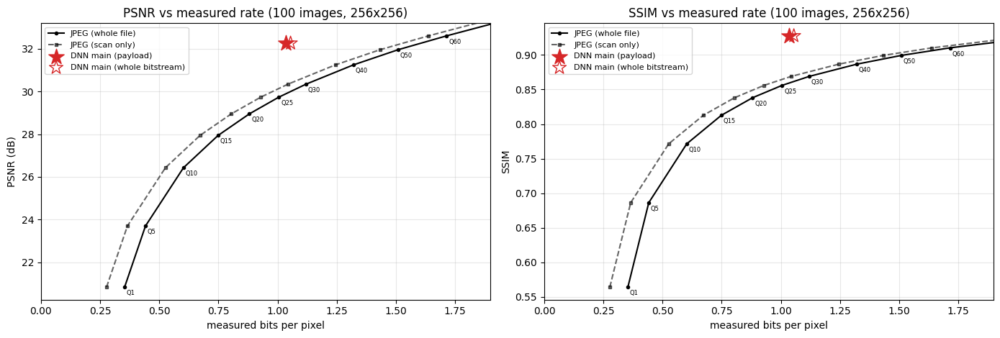

In [26]:
def rd_axes(ax, metric, title, xmax=None):
    ax.plot(JPEG_SUM.bpp_file, JPEG_SUM[metric], 'k-o', ms=3, label='JPEG (whole file)')
    ax.plot(JPEG_SUM.bpp_scan, JPEG_SUM[metric], 'k--s', ms=3, alpha=.6, label='JPEG (scan only)')
    for q, bx, by in zip(JPEG_SUM.Q, JPEG_SUM.bpp_file, JPEG_SUM[metric]): ax.annotate(f'Q{int(q)}', (bx, by), fontsize=6, xytext=(2, -8), textcoords='offset points')
    ax.set(xlabel='measured bits per pixel', ylabel=metric.upper() + (' (dB)' if metric == 'psnr' else ''), title=title); ax.grid(alpha=.3)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, metric in zip(ax, ('psnr', 'ssim')):
    rd_axes(a, metric, f'{metric.upper()} vs measured rate ({N_EVAL} images, {H_EVAL}x{W_EVAL})')
    a.scatter(sm['bpp_payload'], sm[metric], marker='*', s=260, c='tab:red', zorder=5, label='DNN main (payload)')
    a.scatter(sm['bpp_file'], sm[metric], marker='*', s=200, facecolors='none', edgecolors='tab:red', zorder=5, label='DNN main (whole bitstream)')
    top = max(sm['bpp_file'] * 1.8, 1.0); a.set_xlim(0, top)
    visible = JPEG_SUM[JPEG_SUM.bpp_file <= top][metric].tolist() + [sm[metric]]
    pad = 0.05 * (max(visible) - min(visible) + 1e-9); a.set_ylim(min(visible) - pad, max(visible) + pad); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(STAGE / 'figures' / 'rd_dnn_vs_jpeg.png', dpi=160); plt.show()

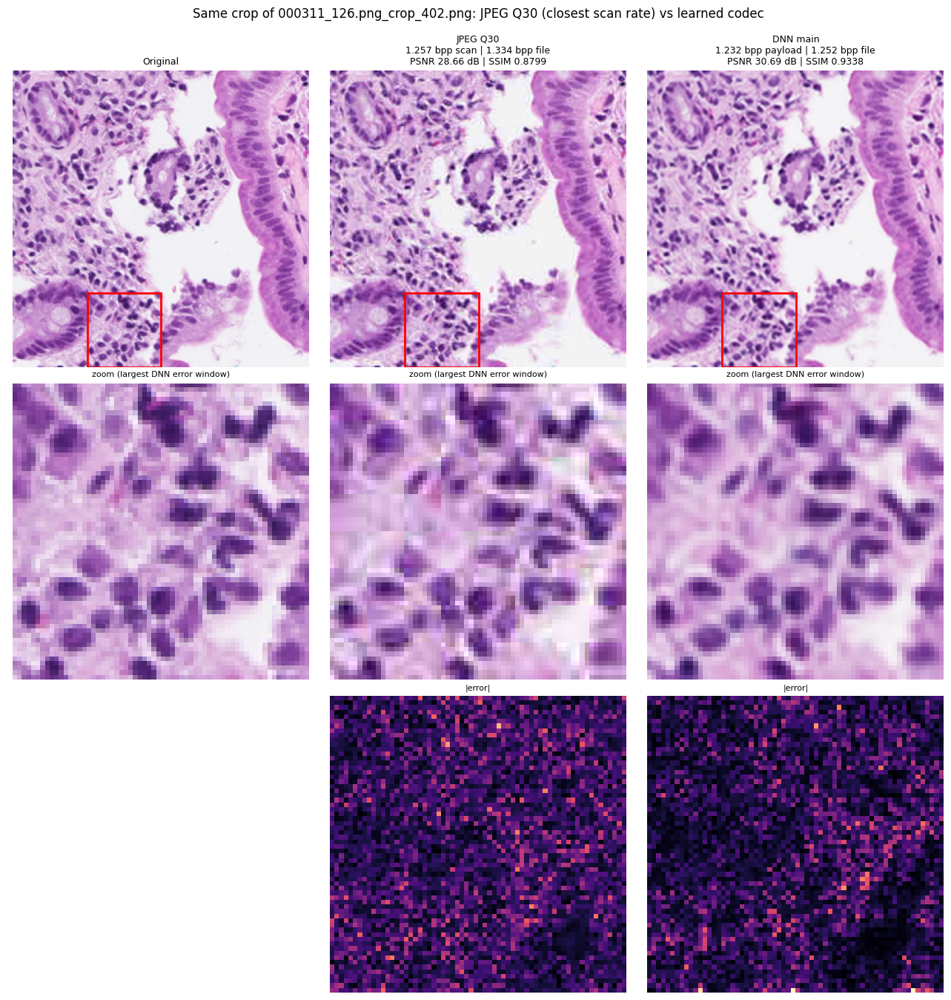

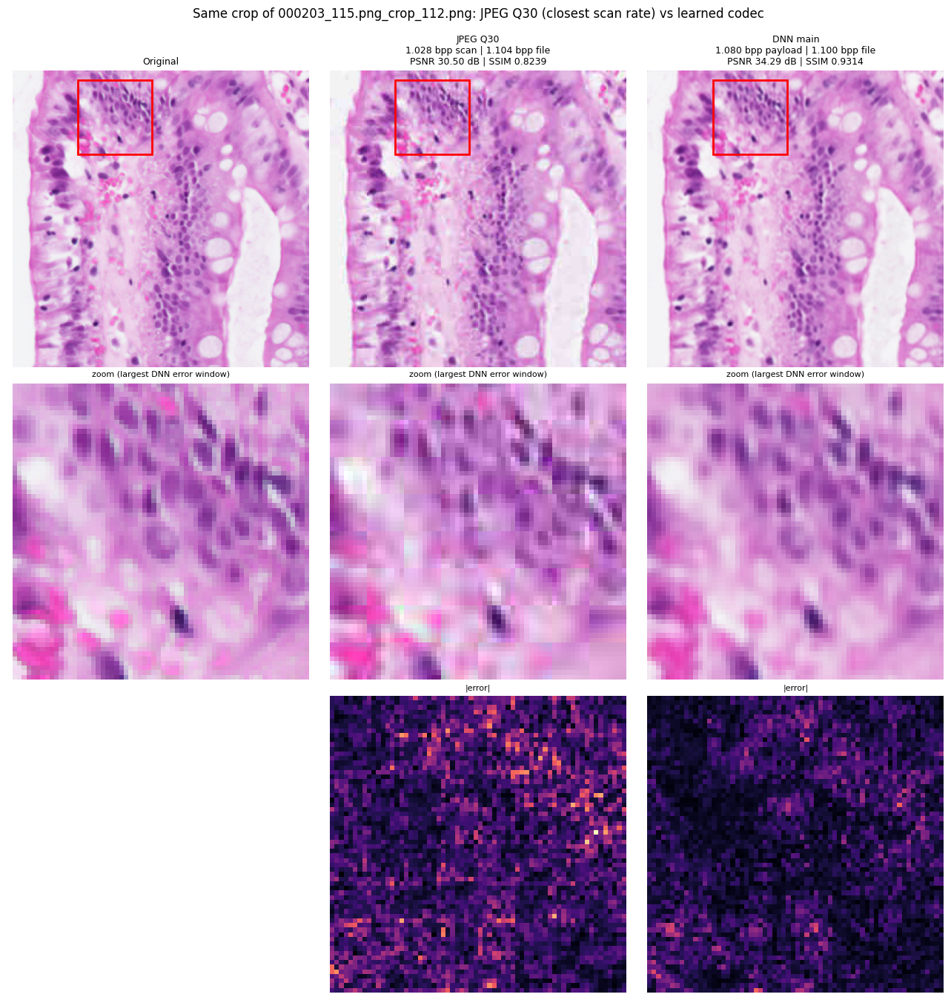

In [27]:
def err_window(err_map, z):
    pooled = F.avg_pool2d(err_map[None, None], z, stride=max(1, z // 8))[0, 0]
    k = int(pooled.argmax()); st = max(1, z // 8)
    return (k // pooled.shape[1]) * st, (k % pooled.shape[1]) * st

def show_jpeg_vs_dnn(img_ids=(0, N_EVAL // 2), q=nearest_q):
    for ii in img_ids:
        t = EVAL_TENSORS[ii]; xi = t[None].to(DEVICE)
        with torch.no_grad(): r_dnn = v_main['cmodel'](xi)['reconstruction'][0].cpu().clamp(0, 1)
        pj, rj = comparison.jpeg_roundtrip(t.permute(1, 2, 0).numpy(), q); r_jpg = torch.from_numpy(rj).permute(2, 0, 1)
        scan = jpeg_scan_bytes(pj); hw = H_EVAL * W_EVAL; z = max(16, H_EVAL // 4)
        ty, tx = err_window((r_dnn - t).abs().mean(0), z)
        cols = [('Original', t, None), (f'JPEG Q{q}\n{8*scan/hw:.3f} bpp scan | {8*len(pj)/hw:.3f} bpp file', r_jpg, True),
                (f"DNN main\n{dm.bpp_payload[ii]:.3f} bpp payload | {dm.bpp_file[ii]:.3f} bpp file", r_dnn, True)]
        vmax = max((r_dnn - t).abs().max().item(), (r_jpg - t).abs().max().item()) * 0.6
        fig, axes = plt.subplots(3, 3, figsize=(13, 13.5))
        for c, (name, im, score) in enumerate(cols):
            title = name
            if score: title += f"\nPSNR {psnr_per_image(im[None], t[None]).item():.2f} dB | SSIM {ssim_per_image(im[None], t[None]).item():.4f}"
            arr = im.permute(1, 2, 0).numpy()
            axes[0, c].imshow(arr); axes[0, c].set_title(title, fontsize=9); axes[0, c].axis('off')
            axes[0, c].add_patch(plt.Rectangle((tx, ty), z, z, fill=False, ec='red', lw=2))
            axes[1, c].imshow(arr[ty:ty + z, tx:tx + z], interpolation='nearest'); axes[1, c].set_title('zoom (largest DNN error window)', fontsize=8); axes[1, c].axis('off')
            if score: axes[2, c].imshow((im - t).abs().mean(0).numpy()[ty:ty + z, tx:tx + z], cmap='magma', vmin=0, vmax=vmax, interpolation='nearest'); axes[2, c].set_title('|error|', fontsize=8)
            axes[2, c].axis('off')
        fig.suptitle(f'Same crop of {EVAL_PATHS[ii].name}: JPEG Q{q} (closest scan rate) vs learned codec', y=0.995)
        fig.tight_layout(); fig.savefig(STAGE / 'figures' / f'jpeg_vs_dnn_example_{ii}.png', dpi=140, bbox_inches='tight'); plt.show(); plt.close(fig)

show_jpeg_vs_dnn()

## 7-10. Controlled ablations: shared tools
Each ablation group changes **one factor** relative to the main model and is evaluated with the identical protocol: same 100 test crops, real bitstreams with the same coder rule (smallest of zlib / left-context / up-context arithmetic coding, tables fitted on training crops only), same metrics. For every group we produce (i) a **rate-distortion plot** with the JPEG curve, (ii) a **table**, (iii) **reconstruction examples** on the same crops with the same zoom window, and (iv) the numbers needed for the limitations discussion (§12).

In [28]:
SHORT = {MAIN_LABEL: 'main'}
STYLE = {}

def variant_table(group, labels):
    rows = []
    jq_ = JPEG_SUM.sort_values('bpp_scan')
    for lab in labels:
        v = VARIANTS[lab]; s = v['summary']; mc, tc = v['model_cfg'], v['train_cfg']
        jp = interp_at(s['bpp_payload'], jq_.bpp_scan, jq_.psnr); js = interp_at(s['bpp_payload'], jq_.bpp_scan, jq_.ssim)
        rows.append(dict(group=group, variant=lab, K=mc['codebook_size'], lam=tc['rate_weight'], straight_through=mc['straight_through'], rate_loss=v['loss_mode'],
                         bpp_payload=s['bpp_payload'], bpp_file=s['bpp_file'], est_bpp=s['est_bpp'], psnr=s['psnr'], psnr_std=s['psnr_std'], ssim=s['ssim'],
                         jpeg_psnr_same_rate=jp, delta_psnr_vs_jpeg=None if jp is None else s['psnr'] - jp,
                         jpeg_ssim_same_rate=js, delta_ssim_vs_jpeg=None if js is None else s['ssim'] - js,
                         used_codewords=s['used_codewords'], perplexity=s['perplexity'], train_minutes=v['minutes'], best_epoch=v['ckpt']['epoch'], coders=str(s['coders'])))
    return pd.DataFrame(rows)

def group_rd_plot(group, labels, fname):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
    xs = [VARIANTS[l]['summary']['bpp_payload'] for l in labels]; xf = [VARIANTS[l]['summary']['bpp_file'] for l in labels]
    for a, metric in zip(ax, ('psnr', 'ssim')):
        rd_axes(a, metric, f'{group}: {metric.upper()} vs measured rate')
        ys = [VARIANTS[l]['summary'][metric] for l in labels]
        a.plot(xs, ys, '-', color='tab:red', alpha=.4)
        for l, x_, y_ in zip(labels, xs, ys):
            a.scatter(x_, y_, s=110, marker='*', c='tab:red', zorder=5); a.annotate(SHORT.get(l, l), (x_, y_), fontsize=8, xytext=(5, 5), textcoords='offset points')
        lo, hi = 0.6 * min(xs), 1.5 * max(xf); a.set_xlim(max(0, lo), hi)
        vis = JPEG_SUM[(JPEG_SUM.bpp_file >= lo) & (JPEG_SUM.bpp_file <= hi)][metric].tolist() + ys
        pad = 0.06 * (max(vis) - min(vis) + 1e-9); a.set_ylim(min(vis) - pad, max(vis) + pad)
        a.scatter([], [], marker='*', c='tab:red', label='DNN variants (payload bpp)'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(STAGE / 'figures' / fname, dpi=160); plt.show()

def group_examples(group, labels, img_ids=(0, N_EVAL // 2), fname_prefix=None):
    for ii in img_ids:
        t = EVAL_TENSORS[ii]; xi = t[None].to(DEVICE); z = max(16, H_EVAL // 4)
        recs = []
        for lab in labels:
            with torch.no_grad(): r = VARIANTS[lab]['cmodel'](xi)['reconstruction'][0].cpu().clamp(0, 1)
            row = VARIANTS[lab]['per_image'].iloc[ii]; recs.append((lab, r, row.bpp_payload, row.psnr, row.ssim))
        ty, tx = err_window((VARIANTS[MAIN_LABEL]['cmodel'](xi)['reconstruction'][0].detach().cpu().clamp(0, 1) - t).abs().mean(0), z)
        vmax = max((r - t).abs().max().item() for _, r, *_ in recs) * 0.6
        ncol = 1 + len(recs); fig, axes = plt.subplots(3, ncol, figsize=(3.6 * ncol, 11))
        axes[0, 0].imshow(t.permute(1, 2, 0)); axes[0, 0].set_title('Original'); axes[1, 0].imshow(t.permute(1, 2, 0).numpy()[ty:ty + z, tx:tx + z], interpolation='nearest'); axes[1, 0].set_title('zoom', fontsize=8)
        axes[2, 0].axis('off')
        for c, (lab, r, bpp, ps, ss) in enumerate(recs, start=1):
            axes[0, c].imshow(r.permute(1, 2, 0)); axes[0, c].set_title(f'{SHORT.get(lab, lab)}\n{bpp:.3f} bpp | {ps:.2f} dB | SSIM {ss:.4f}', fontsize=8)
            axes[1, c].imshow(r.permute(1, 2, 0).numpy()[ty:ty + z, tx:tx + z], interpolation='nearest'); axes[1, c].set_title('zoom', fontsize=8)
            axes[2, c].imshow((r - t).abs().mean(0).numpy()[ty:ty + z, tx:tx + z], cmap='magma', vmin=0, vmax=vmax, interpolation='nearest'); axes[2, c].set_title('|error|', fontsize=8)
        for a in axes.ravel(): a.axis('off')
        for c in range(ncol): axes[0, c].add_patch(plt.Rectangle((tx, ty), z, z, fill=False, ec='red', lw=1.5))
        fig.suptitle(f'{group}: same crop ({EVAL_PATHS[ii].name}), same zoom window', y=0.995)
        fig.tight_layout(); fig.savefig(STAGE / 'figures' / f'{fname_prefix or group}_examples_{ii}.png', dpi=140, bbox_inches='tight'); plt.show(); plt.close(fig)

def finish_group(group, labels):
    GROUPS[group] = labels
    tbl = variant_table(group, labels); tbl.to_csv(STAGE / 'tables' / f'ablation_{group}.csv', index=False)
    pd.set_option('display.width', 250, 'display.max_columns', 40)
    print(tbl[['variant', 'bpp_payload', 'bpp_file', 'est_bpp', 'psnr', 'ssim', 'delta_psnr_vs_jpeg', 'used_codewords', 'perplexity', 'best_epoch']].round(4).to_string(index=False))
    group_rd_plot(group, labels, f'rd_{group}.png'); group_examples(group, labels)
    return tbl

## 7. Ablation 1 - rate multiplier lambda
Only `rate_weight` changes (`1e-4, 1e-3 [main], 1e-2, 1e-1`); everything else identical. Larger lambda weights the relaxed rate term more.

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Epoch 1/80: train=0.00523, hard val PSNR=27.71, SSIM=0.8643, estimated bpp=1.9993
Epoch 2/80: train=0.00385, hard val PSNR=28.16, SSIM=0.8662, estimated bpp=1.9983
Epoch 3/80: train=0.00360, hard val PSNR=28.34, SSIM=0.8694, estimated bpp=1.9970
Epoch 4/80: train=0.00338, hard val PSNR=28.55, SSIM=0.8724, estimated bpp=1.9958
Epoch 5/80: train=0.00319, hard val PSNR=28.70, SSIM=0.8750, estimated bpp=1.9945
Epoch 6/80: train=0.00306, hard val PSNR=28.78, SSIM=0.8772, estimated bpp=1.9929
Epoch 7/80: train=0.00294, hard val PSNR=28.96, SSIM=0.8795, estimated bpp=1.9916
Epoch 8/80: train=0.00289, hard val PSNR=29.11, SSIM=0.8824, estimated bpp

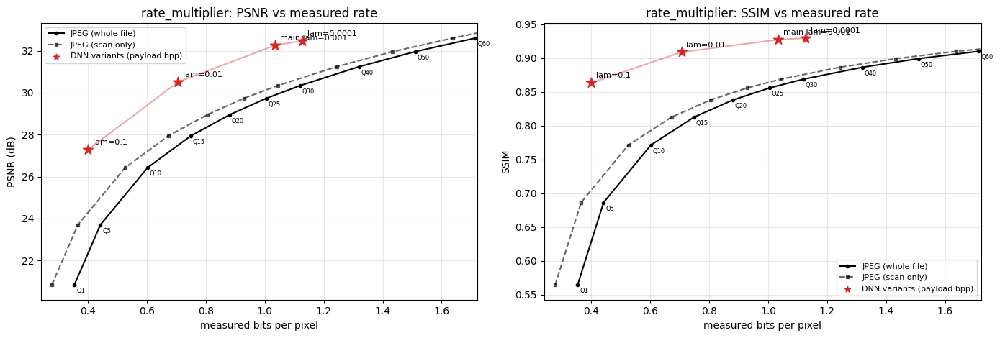

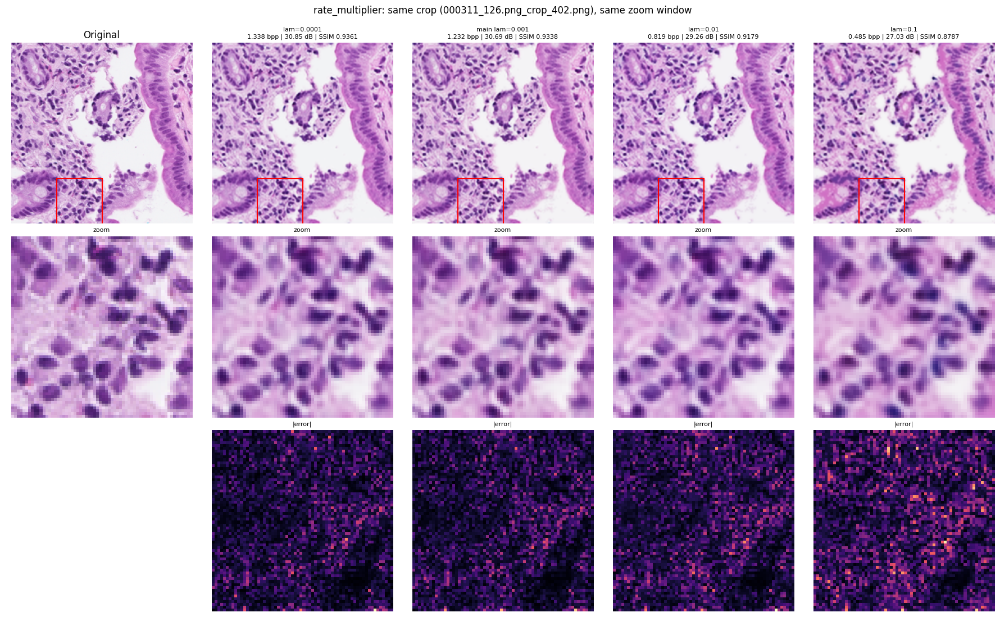

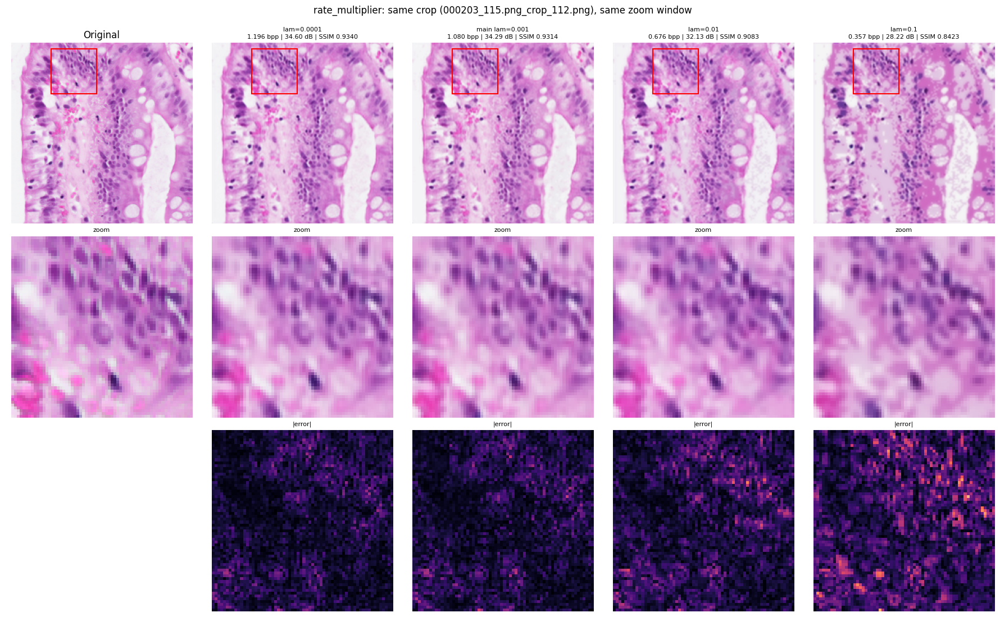

In [29]:
TABLES = {}
if ABLATIONS['rate_multiplier']:
    lam_labels = []
    for lam in ABL_LAMBDAS:
        lab = f'lambda={lam:g}'; SHORT[lab] = f'lam={lam:g}'
        build_variant(lab, MODEL_CONFIG, dict(TRAIN_CONFIG, rate_weight=float(lam)), 'soft')
    SHORT[MAIN_LABEL] = f"main lam={TRAIN_CONFIG['rate_weight']:g}"
    order = sorted([MAIN_LABEL] + [f'lambda={l:g}' for l in ABL_LAMBDAS], key=lambda l: VARIANTS[l]['train_cfg']['rate_weight'])
    TABLES['rate_multiplier'] = finish_group('rate_multiplier', order)

## 8. Ablation 2 - codebook size K
Only `codebook_size` changes (`64, 128, 256 [main], 512`); the fixed-length index cost is `ceil(log2 K)` bits per latent vector.

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Epoch 1/80: train=0.00840, hard val PSNR=27.04, SSIM=0.8448, estimated bpp=1.4989
Epoch 2/80: train=0.00677, hard val PSNR=27.44, SSIM=0.8488, estimated bpp=1.4976
Epoch 3/80: train=0.00645, hard val PSNR=27.60, SSIM=0.8506, estimated bpp=1.4963
Epoch 4/80: train=0.00603, hard val PSNR=27.82, SSIM=0.8544, estimated bpp=1.4950
Epoch 5/80: train=0.00574, hard val PSNR=27.91, SSIM=0.8588, estimated bpp=1.4936
Epoch 6/80: train=0.00554, hard val PSNR=28.10, SSIM=0.8616, estimated bpp=1.4921
Epoch 7/80: train=0.00535, hard val PSNR=28.29, SSIM=0.8620, estimated bpp=1.4907
Epoch 8/80: train=0.00527, hard val PSNR=28.36, SSIM=0.8651, estimated bpp

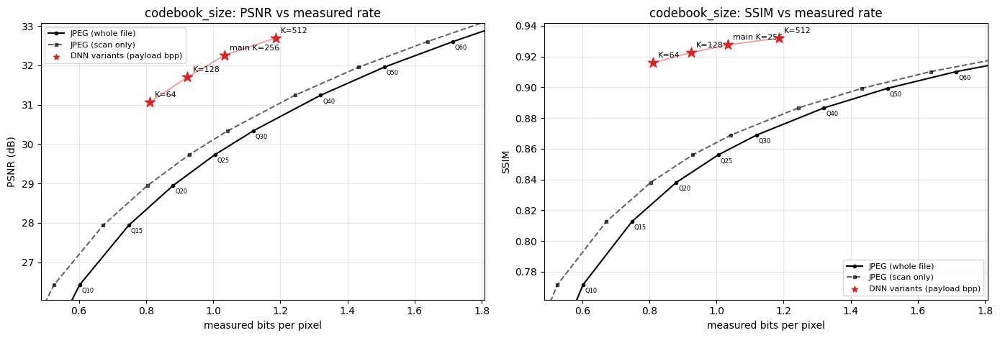

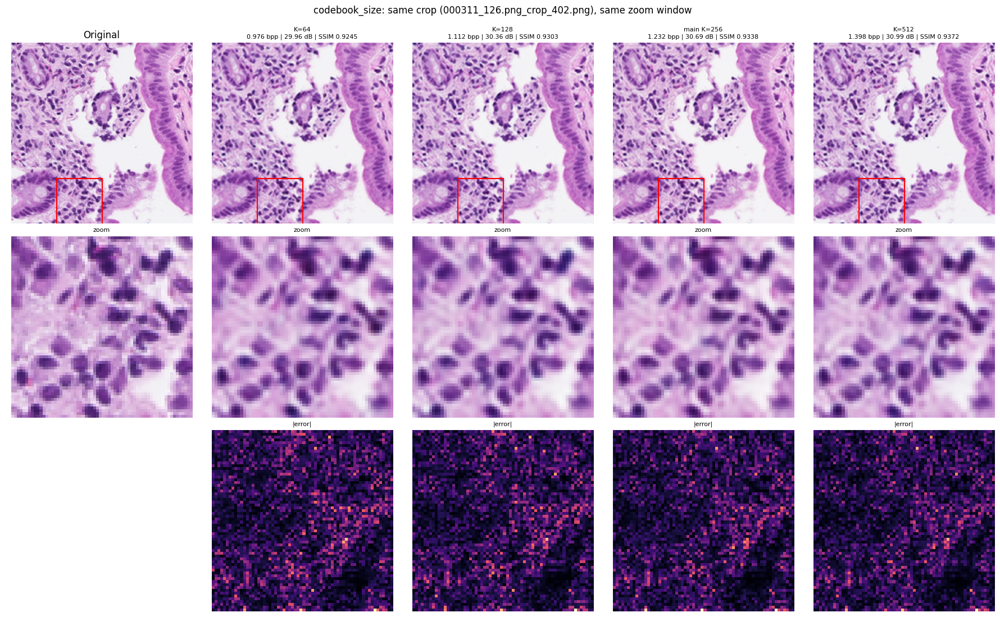

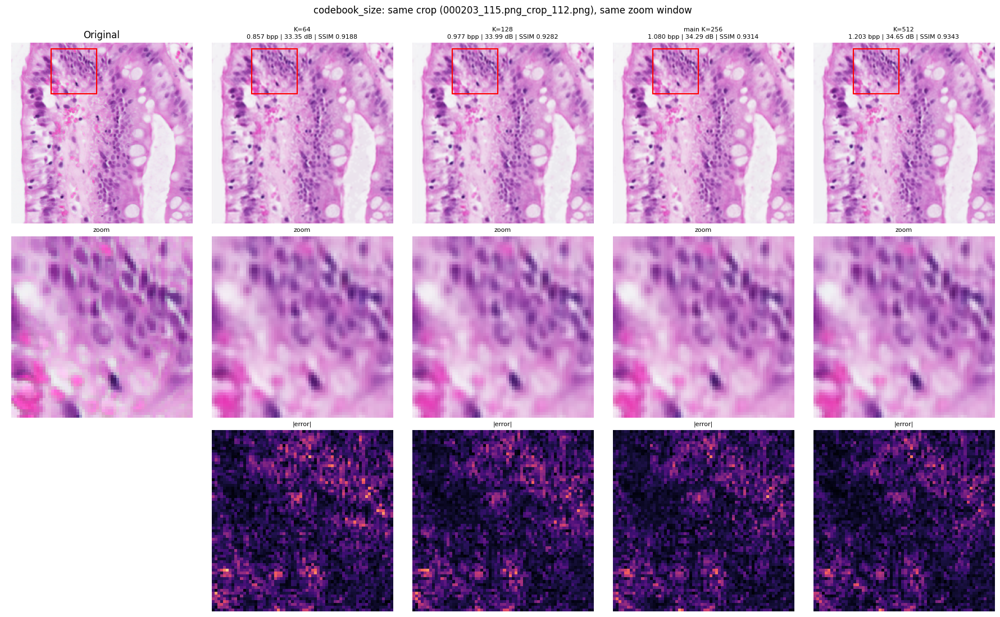

In [30]:
if ABLATIONS['codebook_size']:
    for K_ in ABL_CODEBOOKS:
        lab = f'K={K_}'; SHORT[lab] = lab
        build_variant(lab, dict(MODEL_CONFIG, codebook_size=int(K_)), dict(TRAIN_CONFIG), 'soft')
    SHORT[MAIN_LABEL] = 'main K=256'
    order = sorted([MAIN_LABEL] + [f'K={k}' for k in ABL_CODEBOOKS], key=lambda l: VARIANTS[l]['model_cfg']['codebook_size'])
    TABLES['codebook_size'] = finish_group('codebook_size', order)

## 9. Ablation 3 - quantization strategy
Three strategies, same everything else: **straight-through** (main: hard codeword in the forward pass, soft gradients, relaxed rate), **fully soft** (decoder is trained on the soft mixture, `straight_through=False`), and **hard-index rate / no relaxation** (the rate is computed from the hard indices, so it sends no gradient to the encoder - the paper's "w/o relaxation"). All are decoded with hard assignment from real bitstreams.

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Epoch 1/80: train=0.00682, hard val PSNR=27.39, SSIM=0.8634, estimated bpp=1.9992
Epoch 2/80: train=0.00548, hard val PSNR=28.05, SSIM=0.8657, estimated bpp=1.9980
Epoch 3/80: train=0.00522, hard val PSNR=28.14, SSIM=0.8684, estimated bpp=1.9966
Epoch 4/80: train=0.00497, hard val PSNR=28.36, SSIM=0.8705, estimated bpp=1.9951
Epoch 5/80: train=0.00477, hard val PSNR=28.57, SSIM=0.8729, estimated bpp=1.9935
Epoch 6/80: train=0.00465, hard val PSNR=28.65, SSIM=0.8753, estimated bpp=1.9917
Epoch 7/80: train=0.00452, hard val PSNR=28.64, SSIM=0.8763, estimated bpp=1.9899
Epoch 8/80: train=0.00445, hard val PSNR=28.96, SSIM=0.8788, estimated bpp

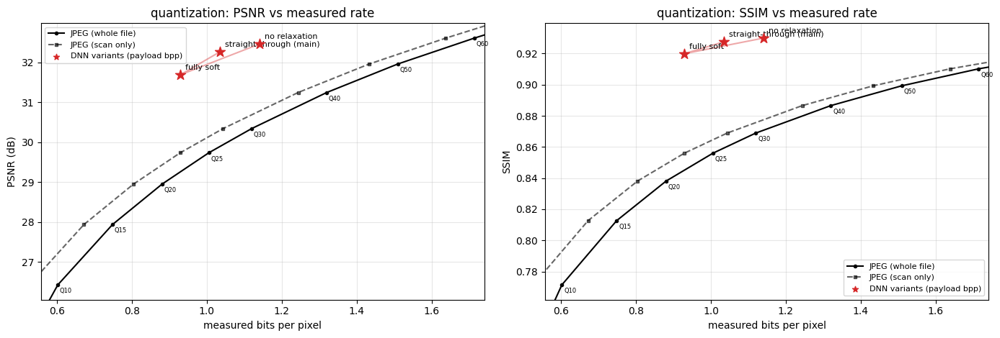

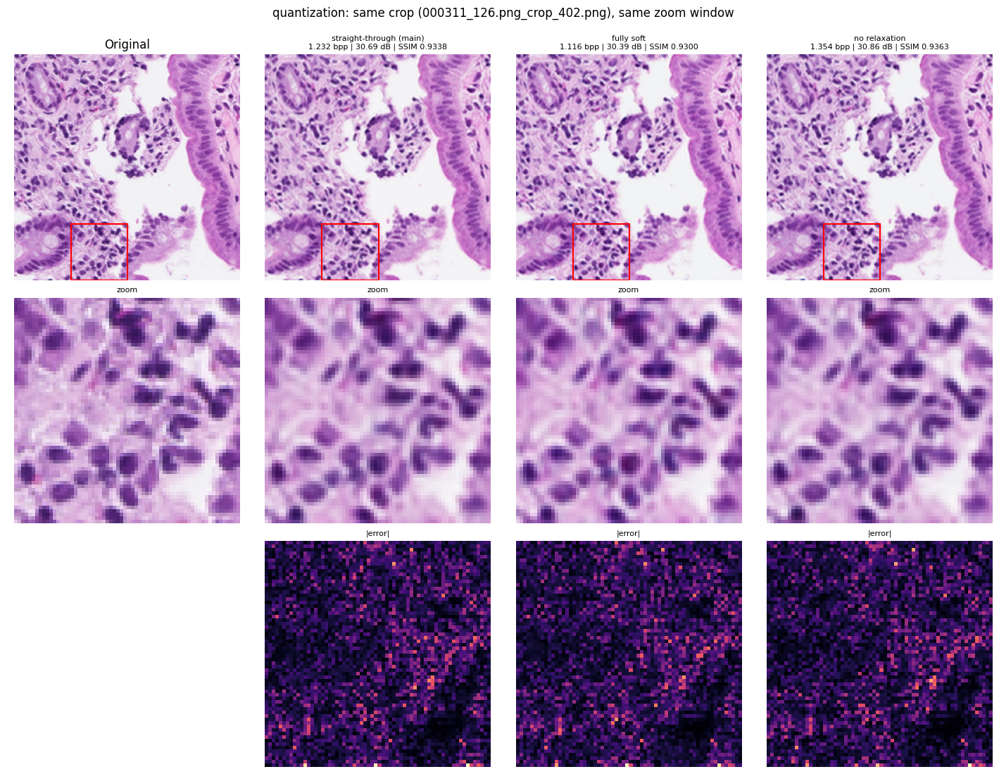

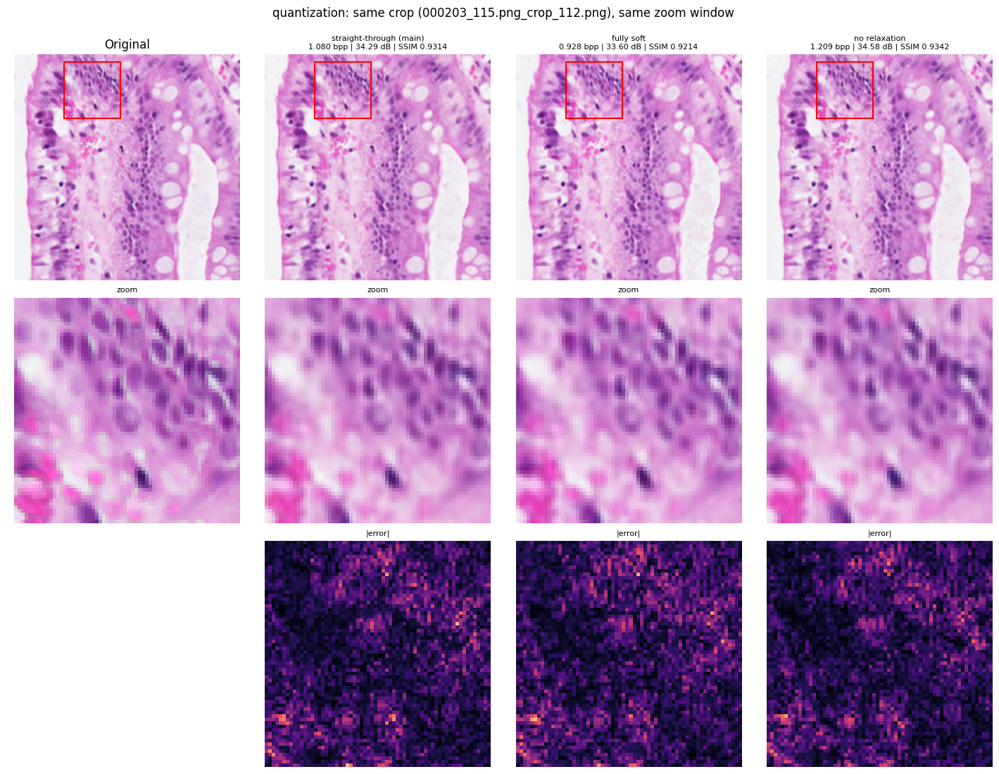

In [31]:
if ABLATIONS['quantization']:
    lab_soft, lab_hard = 'fully soft (straight_through=False)', 'no relaxation (hard-index rate)'
    SHORT.update({lab_soft: 'fully soft', lab_hard: 'no relaxation'}); SHORT[MAIN_LABEL] = 'straight-through (main)'
    build_variant(lab_soft, dict(MODEL_CONFIG, straight_through=False), dict(TRAIN_CONFIG), 'soft')
    build_variant(lab_hard, dict(MODEL_CONFIG), dict(TRAIN_CONFIG), 'hard_rate')
    TABLES['quantization'] = finish_group('quantization', [MAIN_LABEL, lab_soft, lab_hard])

## 10. Ablation 4 - entropy coder (same indices, same reconstruction)
Lossless coders do not change the decoded image, so distortion is identical and only the rate moves. Compared on the main model's indices for all evaluation images: **fixed-length** `ceil(log2 K)` bits, **zlib** on the packed indices, **adaptive arithmetic coding without trained tables** (counts start from the learned prior, left context), and the codec's **trained-table arithmetic coders** (left / up context, fitted on training crops), plus the coder the codec actually selects (smallest per image). The zero-order entropy of the index histogram and the learned-prior estimate are reported as reference points. Arithmetic round trips are verified by decoding.

                                                    bpp_mean  bpp_std  psnr (identical, lossless)  ssim (identical, lossless)
fixed-length                                          2.0000   0.0000                     32.2598                      0.9276
zlib                                                  1.1106   0.3520                     32.2598                      0.9276
arithmetic, adaptive (no trained tables)              1.1743   0.3568                     32.2598                      0.9276
arithmetic-left (trained tables)                      1.0763   0.3550                     32.2598                      0.9276
arithmetic-up (trained tables)                        1.0416   0.3381                     32.2598                      0.9276
codec choice (smallest of zlib/left/up)               1.0347   0.3376                     32.2598                      0.9276
reference: zero-order entropy of index histogram      1.5221      NaN                         NaN                     

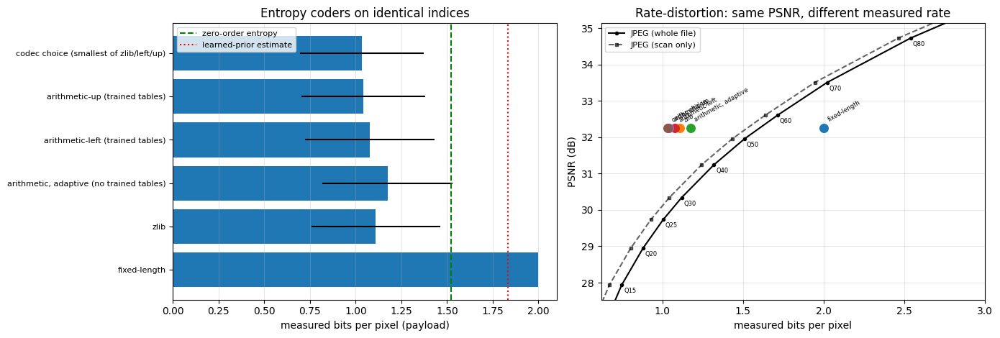

Reconstruction examples: lossless coders decode to exactly the same image (decoded == model output, checked for every image of the main model), so the examples of the main model apply to all coders.


In [32]:
@torch.no_grad()
def entropy_coder_ablation(cmodel, tensors, n_roundtrip=4):
    K = cmodel.config['codebook_size']; width = math.ceil(math.log2(K)); prior = codec_mod._prior(cmodel)
    left, up = cmodel.coder_left.detach().cpu().numpy(), cmodel.coder_up.detach().cpu().numpy()
    rows, counts = [], torch.zeros(K); rt_ok = []
    for i, t in enumerate(tensors):
        xi = t[None].to(DEVICE); h, w = xi.shape[-2:]
        z = cmodel.encode(xi); flat = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1])
        ids = cmodel.hard_indices(flat).cpu().numpy().astype(np.int64).reshape(z.shape[-2], z.shape[-1])
        counts += torch.bincount(torch.from_numpy(ids).flatten(), minlength=K).float()
        packed = codec_mod._packed_indices(ids, width); zl = zlib.compress(packed)
        a_adapt = arith_mod.encode(ids, K, prior, 'left', None)
        a_left = arith_mod.encode(ids, K, prior, 'left', left); a_up = arith_mod.encode(ids, K, prior, 'up', up)
        if i < n_roundtrip:
            for payload, axis, tab in ((a_adapt, 'left', None), (a_left, 'left', left), (a_up, 'up', up)):
                dec = arith_mod.decode(payload, ids.shape[0], ids.shape[1], K, prior, axis, tab)
                rt_ok.append(bool(np.array_equal(np.asarray(dec).reshape(ids.shape), ids)))
        n = h * w
        rows.append({'fixed-length': 8 * len(packed) / n, 'zlib': 8 * len(zl) / n, 'arithmetic, adaptive (no trained tables)': 8 * len(a_adapt) / n,
                     'arithmetic-left (trained tables)': 8 * len(a_left) / n, 'arithmetic-up (trained tables)': 8 * len(a_up) / n,
                     'codec choice (smallest of zlib/left/up)': 8 * min(len(zl), len(a_left), len(a_up)) / n})
    df = pd.DataFrame(rows); p = counts / counts.sum(); nz = p[p > 0]; H0 = float(-(nz * nz.log2()).sum())
    tokens_per_pixel = ids.shape[0] * ids.shape[1] / (H_EVAL * W_EVAL)
    return df, H0 * tokens_per_pixel, all(rt_ok), len(rt_ok)

if ABLATIONS['entropy_coder']:
    CODER_DF, H0_BPP, RT_OK, RT_N = entropy_coder_ablation(v_main['cmodel'], EVAL_TENSORS)
    est_ref = v_main['summary']['est_bpp']
    ct = CODER_DF.agg(['mean', 'std']).T.rename(columns={'mean': 'bpp_mean', 'std': 'bpp_std'})
    ct['psnr (identical, lossless)'] = v_main['summary']['psnr']; ct['ssim (identical, lossless)'] = v_main['summary']['ssim']
    ct.loc['reference: zero-order entropy of index histogram', ['bpp_mean']] = H0_BPP
    ct.loc['reference: learned-prior estimate (training proxy)', ['bpp_mean']] = est_ref
    ct.to_csv(STAGE / 'tables' / 'ablation_entropy_coder.csv'); print(ct.round(4).to_string())
    print(f'arithmetic round trips verified by decoding: {RT_N} streams, all exact = {RT_OK}')
    assert RT_OK, 'arithmetic round-trip failed'
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
    names = list(CODER_DF.columns); means = CODER_DF.mean().values
    ax[0].barh(range(len(names)), means, xerr=CODER_DF.std().values, color='tab:blue'); ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names, fontsize=8)
    ax[0].axvline(H0_BPP, color='g', ls='--', label='zero-order entropy'); ax[0].axvline(est_ref, color='r', ls=':', label='learned-prior estimate'); ax[0].legend(fontsize=8)
    ax[0].set(xlabel='measured bits per pixel (payload)', title='Entropy coders on identical indices'); ax[0].grid(alpha=.3, axis='x')
    rd_axes(ax[1], 'psnr', 'Rate-distortion: same PSNR, different measured rate')
    for nm, mv in zip(names, means): ax[1].scatter(mv, v_main['summary']['psnr'], s=70, zorder=5); ax[1].annotate(nm.split(' (')[0], (mv, v_main['summary']['psnr']), fontsize=6, rotation=30, xytext=(3, 6), textcoords='offset points')
    lo, hi = 0.6 * means.min(), 1.5 * max(means.max(), v_main['summary']['bpp_file']); ax[1].set_xlim(max(0, lo), hi)
    vis = JPEG_SUM[(JPEG_SUM.bpp_file >= lo) & (JPEG_SUM.bpp_file <= hi)].psnr.tolist() + [v_main['summary']['psnr']]; pad = 0.06 * (max(vis) - min(vis) + 1e-9); ax[1].set_ylim(min(vis) - pad, max(vis) + pad)
    ax[1].legend(fontsize=8); fig.tight_layout(); fig.savefig(STAGE / 'figures' / 'rd_entropy_coder.png', dpi=160); plt.show()
    print('Reconstruction examples: lossless coders decode to exactly the same image (decoded == model output, checked for every image of the main model), so the examples of the main model apply to all coders.')

## 11. All variants and the JPEG baseline in one rate-distortion view

                                    variant   K    lam rate_loss  straight_through  bpp_payload  bpp_file    psnr   ssim  delta_psnr_vs_jpeg
main (K=256, lambda=1e-3, straight-through) 256 0.0010      soft              True       1.0347    1.0547 32.2598 0.9276              1.9664
                              lambda=0.0001 256 0.0001      soft              True       1.1282    1.1482 32.4814 0.9298              1.7598
                                lambda=0.01 256 0.0100      soft              True       0.7058    0.7258 30.5106 0.9090              2.3141
                                 lambda=0.1 256 0.1000      soft              True       0.4003    0.4203 27.2906 0.8635              2.9981
                                       K=64  64 0.0010      soft              True       0.8117    0.8317 31.0651 0.9159              2.0687
                                      K=128 128 0.0010      soft              True       0.9236    0.9436 31.7060 0.9226              2.0064
             

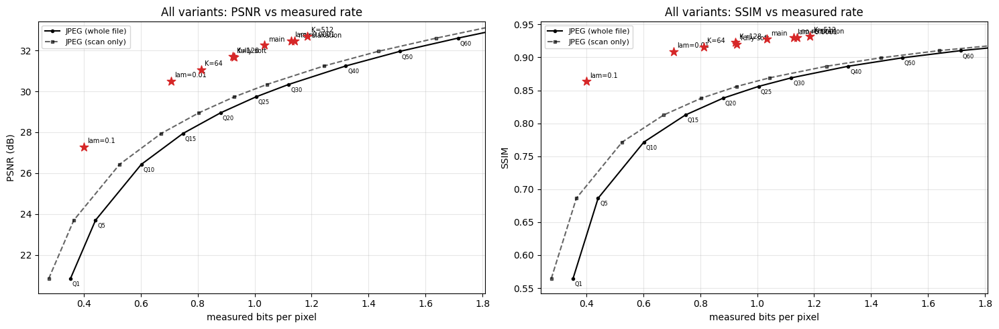

In [33]:
SHORT[MAIN_LABEL] = 'main'
ALL = pd.concat([variant_table('all', list(VARIANTS))], ignore_index=True)
ALL.to_csv(STAGE / 'tables' / 'all_variants_summary.csv', index=False)
for lab, v in VARIANTS.items():
    v['per_image'].to_csv(STAGE / 'tables' / ('per_image_' + re.sub(r'[^A-Za-z0-9]+', '_', lab).strip('_') + '.csv'), index=False)
print(ALL[['variant', 'K', 'lam', 'rate_loss', 'straight_through', 'bpp_payload', 'bpp_file', 'psnr', 'ssim', 'delta_psnr_vs_jpeg']].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
xs = ALL.bpp_payload.values; xf = ALL.bpp_file.values; lo, hi = 0.6 * xs.min(), 1.5 * xf.max()
for a, metric in zip(ax, ('psnr', 'ssim')):
    rd_axes(a, metric, f'All variants: {metric.upper()} vs measured rate')
    a.scatter(xs, ALL[metric], s=90, marker='*', c='tab:red', zorder=5)
    for _, r in ALL.iterrows(): a.annotate(SHORT.get(r.variant, r.variant), (r.bpp_payload, r[metric]), fontsize=7, xytext=(4, 4), textcoords='offset points')
    a.set_xlim(max(0, lo), hi); vis = JPEG_SUM[(JPEG_SUM.bpp_file >= lo) & (JPEG_SUM.bpp_file <= hi)][metric].tolist() + ALL[metric].tolist()
    pad = 0.06 * (max(vis) - min(vis) + 1e-9); a.set_ylim(min(vis) - pad, max(vis) + pad); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(STAGE / 'figures' / 'rd_all_variants_vs_jpeg.png', dpi=160); plt.show()

## 12. Limitations - evidence from this run (for the discussion)
Facts computed from the measurements above; the interpretation is left to the report.

In [36]:
sm = v_main['summary']; dm = v_main['per_image']
jq = JPEG_SUM.sort_values('bpp_scan')
dnn_rates = ALL.bpp_payload.values
inside = [(jq.bpp_scan.min() <= r <= jq.bpp_scan.max()) for r in dnn_rates]
q50 = JPEG_PER_IMAGE[JPEG_PER_IMAGE.Q == 50]
ckpt_bytes = (Path(v_main['run_dir']) / 'best_arithmetic.pt').stat().st_size
facts = [
    f"Seeds: one training seed ({SEED}) per variant; differences between variants are single-run measurements without a seed-to-seed confidence interval.",
    f"Training budget: {len(loaders['train'].dataset)} training crops of {DATA_CONFIG['crop_size']}x{DATA_CONFIG['crop_size']} (from {len(splits['train'])} training images), {TRAIN_CONFIG['epochs']} epochs; "
    f"evaluation uses {H_EVAL}x{W_EVAL} crops, so training and evaluation crop sizes differ; entropy-coder context tables are fitted on 64x64 index maps.",
    f"Evaluation set: {N_EVAL} held-out images (center {H_EVAL}x{W_EVAL} crops, not whole images when the native image is larger); main PSNR std across images = {sm['psnr_std']:.2f} dB.",
    f"Entropy model: context-free learned prior (estimated {sm['est_bpp']:.3f} bpp) versus measured payload {sm['bpp_payload']:.3f} bpp ({sm['est_bpp'] / sm['bpp_payload'] - 1:+.1%}); "
    f"coders actually selected: {sm['coders']}. No conditional (autoregressive/Transformer) entropy model as in the paper.",
    f"Rate range: DNN variants span {dnn_rates.min():.3f}-{dnn_rates.max():.3f} bpp (payload); measured JPEG scan range is {jq.bpp_scan.min():.3f}-{jq.bpp_scan.max():.3f} bpp; "
    f"{int(sum(inside))}/{len(inside)} variants lie inside the measured JPEG range (equal-rate comparison exists only there).",
    f"Container overhead: DNN header averages {(dm.file_bytes - dm.payload_bytes).mean():.0f} B/image vs JPEG headers {(q50.file_bytes - q50.scan_bytes).mean():.0f} B/image (Q50).",
    f"Shared model (network + codebook + context tables) = {ckpt_bytes / 1e3:.0f} kB, excluded from per-image rates; JPEG needs no such shared file.",
    f"Speed: Python arithmetic coder, mean encode {sm['enc_ms']:.0f} ms and decode {sm['dec_ms']:.0f} ms per {H_EVAL}x{W_EVAL} image (CPU coder + GPU network).",
    "Distortion is MSE plus the codebook term only (no LPIPS/GAN); quality is judged with PSNR and SSIM only.",
    "Single-scale latent (downsampling 2), codebook of K= 64-512 codewords (main K =256 ) of dimension 16, about 0.2 M parameters: far smaller than the paper's multi-scale 4096x32 system.",
]
LIMITS_MD = '# Limitations: evidence from this run\n\n' + '\n'.join('- ' + f for f in facts)
(STAGE / 'limitations_evidence.md').write_text(LIMITS_MD); print(LIMITS_MD)

# Limitations: evidence from this run

- Seeds: one training seed (1512) per variant; differences between variants are single-run measurements without a seed-to-seed confidence interval.
- Training budget: 1024 training crops of 64x64 (from 12616 training images), 80 epochs; evaluation uses 256x256 crops, so training and evaluation crop sizes differ; entropy-coder context tables are fitted on 64x64 index maps.
- Evaluation set: 100 held-out images (center 256x256 crops, not whole images when the native image is larger); main PSNR std across images = 2.06 dB.
- Entropy model: context-free learned prior (estimated 1.831 bpp) versus measured payload 1.035 bpp (+77.0%); coders actually selected: {'arithmetic-up': np.int64(72), 'arithmetic-left': np.int64(18), 'zlib': np.int64(10)}. No conditional (autoregressive/Transformer) entropy model as in the paper.
- Rate range: DNN variants span 0.400-1.185 bpp (payload); measured JPEG scan range is 0.277-5.478 bpp; 9/9 variants lie inside the meas

## 13. Reproducibility record and download
Records dataset splits, image sizes (native and crop), JPEG settings, seeds, codebook settings, rate-accounting rules and the measured index-decoding checks, then packages tables, figures, checkpoints and the record into one zip that downloads automatically.

In [35]:
decode_checks = {lab: dict(images_decoded_from_bytes=v['summary']['decode_checked'], max_abs_decoded_minus_model=v['summary']['max_decode_err']) for lab, v in VARIANTS.items()}
record = dict(
    part='4', seed=SEED, device=str(DEVICE), torch=torch.__version__, torchmetrics=torchmetrics.__version__,
    gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    data_root=str(DATA_ROOT), split_rule='predefined train/val/test directories', manifest=str(SPLIT_MANIFEST), split_sizes_full={s: len(v) for s, v in splits.items()},
    training_crops=len(loaders['train'].dataset), validation_crops=len(loaders['val'].dataset), limits=LIMITS,
    evaluation=dict(n_images=N_EVAL, test_offset=TEST_OFFSET, selection='shuffled test list [TEST_OFFSET: TEST_OFFSET+N_EVAL] (same source images as the Part 3 test slice)',
                    native_sizes={str(k): v for k, v in sizes.items()}, file_formats=dict(fmts), crop=f'{H_EVAL}x{W_EVAL} center crop', train_crop=DATA_CONFIG['crop_size'],
                    images=[p.name for p in EVAL_PATHS]),
    jpeg_settings=dict(library='Pillow ' + Image.__version__, subsampling='4:4:4', optimize=False, qualities=list(JPEG_QUALITIES),
                       rates='file bpp = 8*file bytes/(H*W); scan bpp = entropy-coded scan only'),
    model_config=MODEL_CONFIG, train_config=TRAIN_CONFIG, codebook_loss=CODEBOOK_LOSS, warm_start=dict(enabled=USE_WARM_START, epochs=8, max_vectors=32768),
    variants={lab: dict(model_cfg=v['model_cfg'], rate_weight=v['train_cfg']['rate_weight'], rate_loss=v['loss_mode'], codebook=dict(K=v['model_cfg']['codebook_size'], dim=v['model_cfg']['latent_dim'],
              bits_per_index=math.ceil(math.log2(v['model_cfg']['codebook_size']))), best_epoch=v['ckpt']['epoch'], train_minutes=v['minutes'], run_dir=str(v['run_dir'])) for lab, v in VARIANTS.items()},
    rate_accounting=dict(dnn_payload='8*compressed latent payload bytes/(H*W)', dnn_file='8*len(bitstream)/(H*W) incl. header', jpeg_file='8*complete .jpg bytes/(H*W)',
                         jpeg_scan='8*entropy-coded scan bytes/(H*W)', excluded='shared checkpoint (network, codebook, context tables)', estimated_bpp='training proxy only, never reported as a measured size',
                         coder_rule='smallest of zlib / arithmetic-left / arithmetic-up per image; context tables fitted on training crops only'),
    index_decoding_checks=dict(per_variant=decode_checks, arithmetic_roundtrip=dict(streams=RT_N if ABLATIONS['entropy_coder'] else None, all_exact=RT_OK if ABLATIONS['entropy_coder'] else None),
                               criterion='decompress(compress(x)) equals the model reconstruction, max abs diff < 1e-4'),
    equal_rate_comparison_main=json.loads(EQ.to_json(orient='records')),
)
(STAGE / 'part4_reproducibility.json').write_text(json.dumps(record, indent=2, default=str))
print(json.dumps({k: record[k] for k in ('seed', 'split_sizes_full', 'training_crops', 'evaluation', 'jpeg_settings')}, indent=2, default=str)[:2500])

import shutil
BUNDLE = PROJECT_DIR / 'part4_bundle'
if BUNDLE.exists(): shutil.rmtree(BUNDLE)
shutil.copytree(STAGE, BUNDLE / 'part4_results')
shutil.copytree(OUTPUT_ROOT, BUNDLE / 'runs', ignore=shutil.ignore_patterns('last.pt'))
archive = shutil.make_archive('/content/part4_results' if IN_COLAB else str(Path.cwd() / 'part4_results'), 'zip', BUNDLE)
print('Archive:', archive, f'({Path(archive).stat().st_size / 1e6:.1f} MB)')
if IN_COLAB:
    colab_files.download(archive)

{
  "seed": 1512,
  "split_sizes_full": {
    "train": 12616,
    "val": 1576,
    "test": 1576
  },
  "training_crops": 1024,
  "evaluation": {
    "n_images": 100,
    "test_offset": 128,
    "selection": "shuffled test list [TEST_OFFSET: TEST_OFFSET+N_EVAL] (same source images as the Part 3 test slice)",
    "native_sizes": {
      "(272, 272)": 100
    },
    "file_formats": {
      "PNG": 100
    },
    "crop": "256x256 center crop",
    "train_crop": 64,
    "images": [
      "000311_126.png_crop_402.png",
      "001096_161.png_crop_1467.png",
      "000336_124_R01.png_crop_50.png",
      "000406_167.png_crop_253.png",
      "000116_171.png_crop_3183.png",
      "000656_134_R02.png_crop_234.png",
      "000287_P13_R03.png_crop_56.png",
      "001539_P2.png_crop_3.png",
      "000010_BY63_R02.png_crop_1337.png",
      "001337_005.png_crop_2907.png",
      "001371_143_R04.png_crop_192.png",
      "000524_167.png_crop_487.png",
      "000475_123_R01.png_crop_271.png",
      "000876_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>